# 04 · KAIST ↔ Boreas: domain-shift and FM perturbation laboratory

This notebook compares the frozen FM .11 checkpoint across authentic KAIST and Boreas measurements, measures raw and token-level domain shift, and supports reversible in-memory augmentations before `GeometryProcessor`.

**KAIST reference comes from notebook 55** (`55_train_pooled_calibration_fm_bounded_updates`): the physical 3-sensor rig uses `imu`, `lidar` (left), `lidar_right`; `T_B_I = inv(T_I_B)`, both distinct LiDAR extrinsics, and the separate `/home/camel/Skoltech/phd_proposal/data/KAISTDataset` pose root. The KAIST rig is the *nominal physical rig*, not the independently randomized `true_calibration` augmentation used during training. Notebook 55 trains FM .12, not FM .11: validate that the FM .11 experiment used the same rig/dataset conventions before interpreting cross-domain numerical metrics.

**Default topology:** KAIST (one IMU + two LiDARs) versus Boreas (DMU + Velodyne + Aeva LiDAR), matching the number of physical sensors and calibration heads. Switch Boreas topology to isolate individual LiDARs.

**Key limitations:** Boreas's calibration matrices are nominal references, not independent verified extrinsic truth. Neither Applanix pose nor any other GT-derived relative LiDAR transform is supplied to FM. No dataset files or checkpoint weights are modified. Chronological KAIST rollouts remain disabled until actual physical window continuity is verified.

## 1. Configuration: paths, native windows, checkpoints, and chosen topology

In [7]:
from pathlib import Path
import os
import numpy as np

RUN_NAME = "kaist_boreas_fm_domain_shift_lab"
KAIST_ROOT = Path(os.environ.get("KAIST_DATA_ROOT", "/mnt/d/Downloads/MobRobLab/KAISTDataset"))
# Notebook 55's separately produced LiDAR odometry pose CSVs are NOT under KAIST_ROOT.
KAIST_LIDAR_ROOT = Path(os.environ.get("KAIST_LIDAR_ROOT", "/home/camel/Skoltech/phd_proposal/data/KAISTDataset"))
KAIST_LIDAR_RIGHT_POSE_FILENAME = "lidar_map_poses_vlp_right.csv"
KAIST_TRAIN_SEQUENCES = ("Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16")
KAIST_VAL_SEQUENCES = ("Urban26", "Urban28")
KAIST_TEST_SEQUENCES = ("Urban38", "Urban39")
KAIST_SEQUENCE = "Urban08"  # Seen-training-sequence baseline to test "break KAIST"; Urban38 is held-out in notebook 55.
KAIST_EXPECTED_KEYS = ("imu", "lidar", "lidar_right")
KAIST_MAX_SAMPLES_PER_SENSOR = 700  # From notebook 55; independent of Boreas's sample cap.
KAIST_REFERENCE_SOURCE = "55_train_pooled_calibration_fm_bounded_updates(1).ipynb, physical rig, Section 3"

# Exact nominal KAIST physical rig from notebook 55, *not* the per-window randomized training truth.
KAIST_T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0,  0.00],
    [0.0, 0.0, 1.0,  1.70],
    [0.0, 0.0, 0.0,  1.00],
], dtype=np.float64)
KAIST_T_B_I = np.linalg.inv(KAIST_T_I_B)
KAIST_T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=np.float64)
KAIST_T_B_L_RIGHT = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=np.float64)
KAIST_RIG_JSON = None  # Optional override for all THREE transforms, not just left LiDAR.
# JSON keys: T_B_I, T_B_L, T_B_L_right; optional tau_imu_s, tau_lidar_s, tau_lidar_right_s.
KAIST_TAU_IMU_S = 0.0
KAIST_TAU_LIDAR_S = 0.0
KAIST_TAU_LIDAR_RIGHT_S = 0.0
REQUIRE_VALID_KAIST_RIG_FOR_FM = True

BOREAS_ROOT = os.environ.get("BOREAS_DATA_ROOT")
BOREAS_SEQUENCE = "boreas-2024-12-03-12-54"
FM_CHECKPOINT = Path("runs/kaist_pooled_calibration_fm.11_three_stage_full/best.pt")
REGRESSION_CHECKPOINT = Path("runs/kaist_pooled_calibration_paired_002.26_refined_tau_single_topology_light/best.pt")
RUN_REGRESSION = False

BOREAS_TOPOLOGIES = {
    "dmu_velodyne": ("imu_dmu", "lidar_velodyne"),
    "dmu_aeva": ("imu_dmu", "lidar_aeva"),
    "aeva_velodyne": ("imu_aeva", "lidar_velodyne"),
    "aeva_aeva": ("imu_aeva", "lidar_aeva"),
    "2imu_velodyne": ("imu_dmu", "imu_aeva", "lidar_velodyne"),
    "2imu_aeva": ("imu_dmu", "imu_aeva", "lidar_aeva"),
    "dmu_2lidars": ("imu_dmu", "lidar_velodyne", "lidar_aeva"),
    "aeva_2lidars": ("imu_aeva", "lidar_velodyne", "lidar_aeva"),
    "all_four": ("imu_dmu", "imu_aeva", "lidar_velodyne", "lidar_aeva"),
}
BOREAS_TOPOLOGY = "dmu_2lidars"  # Three physical sensors / three calibration heads, as for KAIST.
BOREAS_LIDAR_SCAN_ODOM = True  # Independent ICP caches; never Applanix-derived GT edges.

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_WINDOWS_PER_DOMAIN = 30
MAX_BOREAS_DURATION_S = 180.0
BOREAS_START_OFFSET_S = 0.0
MAX_IMU_SAMPLES_PER_WINDOW = 700  # Boreas cap (KAIST has a separate cap mirroring notebook 55)
MAX_LIDAR_EDGES_PER_WINDOW = 200
MIN_IMU_SAMPLES = 8
MIN_LIDAR_EDGES = 2
MAX_IMU_GAP_S = 0.5

DEVICE_NAME = "cuda"
DTYPE_NAME = "float32"
FM_STEPS = 16
FM_METHOD = "midpoint"
RANDOM_SEED = 20261107
PLOT_MAX_POINTS = 50_000
SAVE_PLOTS = True
SHOW_PLOTS = True
RUN_MOTION_CONSISTENCY = True
RUN_TOKEN_ANALYSIS = True
RUN_ONE_STEP = True
RUN_ROLLOUTS = True
RUN_ABLATION_GRID = True
EVALUATION_WINDOWS = (0, 5, 10)
FAULT_ANGLES_DEG = (0.0, 15.0, 45.0, 90.0, 130.0, 170.0)
FAULT_AXES = (0, 1, 2)
FOCUS_FAULT_ANGLES_DEG = (0.0, 45.0, 130.0)
FOCUS_FAULT_AXIS = 2
ROLLOUT_WINDOW_COUNT = 15
KAIST_ASSUME_CONSECUTIVE_VALID_WINDOWS = False  # Window index * stride is NOT proof of physical continuity.
ROLLOUT_CONVERGENCE_DEG = 5.0
ROLL_ROTATION_GAIN = 1.0
MAX_ROTATION_STEP_DEG = None
ACTIVE_DOMAINS = ("kaist", "boreas")

## 2. Imports, repository discovery, and calibration reference validation

In [8]:
import copy
import dataclasses
import json
import sys
import warnings
import zlib
from dataclasses import dataclass, replace
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as Rot
from scipy.stats import wasserstein_distance
from IPython.display import display
from tqdm.auto import tqdm

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "obscalib").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open Jupyter from within nn-obs-calib (need src/obscalib).")
sys.path.insert(0, str(ROOT / "src"))
from boreas_dataset.dataset import BoreasDataset
from boreas_dataset.odometry import load_lidar_data_csv
from boreas_dataset.calibration import validate_rigid_transform
from boreas_dataset.timing import relative_seconds, timestamps_to_ns
from obscalib.config import (CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig,
    PooledCalibrationModelConfig, PooledCalibrationFlowConfig, CalibrationFlowIntegratorConfig,
    TransformerConfig, WindowingConfig)
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.context import calibration_state_to_context
from obscalib.data.structures import WindowBatch, SensorStreamBatch, SensorMetadata
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.training.checkpoint import load_training_checkpoint

DEVICE = torch.device("cuda" if DEVICE_NAME == "cuda" and torch.cuda.is_available() else "cpu")
MODEL_DTYPE = getattr(torch, DTYPE_NAME)
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
OUT = ROOT / "outputs" / "plots" / RUN_NAME
if SAVE_PLOTS: OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.23,
                     "axes.spines.top": False, "axes.spines.right": False})

def finish_plot(fig, filename):
    fig.tight_layout()
    if SAVE_PLOTS: fig.savefig(OUT / filename, dpi=155, bbox_inches="tight")
    if SHOW_PLOTS: plt.show()
    plt.close(fig)

def valid_transform(name, value):
    """Accept one rigid transform (4,4) or a batch (...,4,4) of SE(3) transforms.

    This is used for both calibration matrices and native LiDAR streams [N,4,4].
    It deliberately does not reshape or drop the sample dimension.
    """
    T = np.asarray(value, dtype=np.float64)
    if T.ndim < 2 or T.shape[-2:] != (4, 4):
        raise ValueError(f"{name}: expected (..., 4, 4) SE(3) matrix/matrices, got {T.shape}")
    return validate_rigid_transform(T)

if KAIST_RIG_JSON is not None:
    rig_file = Path(KAIST_RIG_JSON).expanduser()
    rig = json.loads(rig_file.read_text(encoding="utf-8"))
    missing_rig = sorted({"T_B_I", "T_B_L", "T_B_L_right"} - set(rig))
    if missing_rig:
        raise ValueError(f"KAIST rig JSON must supply all 3 physical transforms; missing {missing_rig}")
    KAIST_T_B_I, KAIST_T_B_L, KAIST_T_B_L_RIGHT = rig["T_B_I"], rig["T_B_L"], rig["T_B_L_right"]
    KAIST_TAU_IMU_S = float(rig.get("tau_imu_s", KAIST_TAU_IMU_S))
    KAIST_TAU_LIDAR_S = float(rig.get("tau_lidar_s", KAIST_TAU_LIDAR_S))
    KAIST_TAU_LIDAR_RIGHT_S = float(rig.get("tau_lidar_right_s", KAIST_TAU_LIDAR_RIGHT_S))
    KAIST_REFERENCE_SOURCE = str(rig_file)
KAIST_REFERENCE_READY = all(x is not None for x in (KAIST_T_B_I, KAIST_T_B_L, KAIST_T_B_L_RIGHT))
if KAIST_REFERENCE_READY:
    KAIST_T_B_I = valid_transform("KAIST_T_B_I", KAIST_T_B_I)
    KAIST_T_B_L = valid_transform("KAIST_T_B_L", KAIST_T_B_L)
    KAIST_T_B_L_RIGHT = valid_transform("KAIST_T_B_L_RIGHT", KAIST_T_B_L_RIGHT)
else:
    warnings.warn("KAIST physical rig incomplete: all three extrinsics are required for FM evaluation.")
print("Project:", ROOT, "| device:", DEVICE, "| KAIST physical rig:", KAIST_REFERENCE_READY)
print("KAIST physical rig source:", KAIST_REFERENCE_SOURCE)
assert BOREAS_TOPOLOGY in BOREAS_TOPOLOGIES and FM_STEPS >= 1 and FM_METHOD in ("euler", "midpoint")

Project: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | device: cuda | KAIST physical rig: True
KAIST physical rig source: 55_train_pooled_calibration_fm_bounded_updates(1).ipynb, physical rig, Section 3


### KAIST physical setup from notebook 55

- Native data root: `/mnt/d/Downloads/MobRobLab/KAISTDataset`.
- LiDAR pose root: `/home/camel/Skoltech/phd_proposal/data/KAISTDataset`. **These are different directories**.
- The loader uses `lidar_map_poses_vlp_right.csv` for the second LiDAR; keep both left and right LiDAR streams.
- Physical rig: `T_B_I=inv(T_I_B)`, `T_B_L`, and `T_B_L_right` from notebook 55; three calibration keys: `("imu", "lidar", "lidar_right")`.
- Window duration/stride: 5 s / 5 s; KAIST sensor cap: 700 samples per window (as in notebook 55).
- Training splits in notebook 55: train = Urban08/12/13/14/15/16, val = Urban26/28, test = Urban38/39. The default here is Urban08 to test whether an augmentation **breaks a known training-domain sequence**. Change to Urban38 for a held-out KAIST sequence.
- The nominal physical rig is **not** the randomized `true_calibration` augmentation enabled in notebook 55. FM .11 belongs to a different experiment from notebook 55's FM .12, so confirm its training provenance before treating the above split/reference as exact for FM .11.

If you override the calibration with JSON, supply `T_B_I`, `T_B_L`, and `T_B_L_right`. Never evaluate the right LiDAR with an identity placeholder.

## 3. KAIST: native dataset adapter (reuse original project loader)

In [9]:
KAIST_READY = False
kaist_ds = None
kaist_windows = []
kaist_window_starts = []
if "kaist" in ACTIVE_DOMAINS:
    from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
    if not KAIST_ROOT.is_dir() or not KAIST_LIDAR_ROOT.is_dir():
        raise FileNotFoundError(f"KAIST dataset directories missing:\n raw={KAIST_ROOT}\n odometry={KAIST_LIDAR_ROOT}")
    if not KAIST_REFERENCE_READY:
        raise ValueError("KAIST FM analysis requires all three physical rig matrices from notebook 55")

    rig = KAISTRigCalibration(
        T_B_I=KAIST_T_B_I, T_B_L=KAIST_T_B_L, T_B_L_right=KAIST_T_B_L_RIGHT,
        tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S,
        tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S,
    )
    specs = build_kaist_sequence_specs(
        sequence_names=[KAIST_SEQUENCE],
        kaist_dataset_root=KAIST_ROOT,
        lidar_pose_root=KAIST_LIDAR_ROOT,
        lidar_right_pose_filename=KAIST_LIDAR_RIGHT_POSE_FILENAME,
    )
    for spec in specs:
        right_csv = getattr(spec, "lidar_right_pose_csv", None)
        if right_csv is None or not Path(right_csv).is_file():
            raise FileNotFoundError(f"Right LiDAR pose CSV required for {spec.name}: {right_csv}. "
                                    "Check KAIST_LIDAR_ROOT and KAIST_LIDAR_RIGHT_POSE_FILENAME")
    kaist_ds = KAISTCalibrationDataset(
        specs, rig,
        WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S,
                        max_samples_per_sensor=KAIST_MAX_SAMPLES_PER_SENSOR),
        measurement_dtype=MODEL_DTYPE, source_timestamp_dtype=torch.float64,
        window_timestamp_dtype=MODEL_DTYPE,
    )
    if tuple(kaist_ds.calibration_keys) != KAIST_EXPECTED_KEYS:
        raise AssertionError(f"KAIST calibration keys differ from notebook 55: "
                             f"{kaist_ds.calibration_keys} != {KAIST_EXPECTED_KEYS}")
    n_kaist = min(len(kaist_ds), MAX_WINDOWS_PER_DOMAIN)
    if n_kaist < 2:
        raise ValueError("Need at least two KAIST windows")
    for i in range(n_kaist):
        sample = collate_windows([kaist_ds[i]])
        if not isinstance(sample, WindowBatch):
            raise TypeError("Expected collate_windows to return WindowBatch")
        if tuple(sample.current_calibration) != KAIST_EXPECTED_KEYS:
            raise AssertionError(f"Unexpected KAIST window keys {tuple(sample.current_calibration)}")
        kaist_windows.append(sample)
        # Plot-index scale ONLY. Confirm actual physical starts before enabling KAIST rollouts.
        kaist_window_starts.append(i * WINDOW_STRIDE_S)

    nominal = {"imu": KAIST_T_B_I, "lidar": KAIST_T_B_L, "lidar_right": KAIST_T_B_L_RIGHT}
    for k, reference_T in nominal.items():
        actual = kaist_windows[0].current_calibration[k].transform[0].detach().cpu().numpy()
        np.testing.assert_allclose(actual, reference_T, rtol=0.0, atol=2e-5,
                                   err_msg=f"KAIST {k} is not initialized with the physical rig")
    KAIST_READY = True
    print(f"KAIST {KAIST_SEQUENCE}: {len(kaist_windows)} windows; keys={tuple(kaist_ds.calibration_keys)}")
    print("Physical LiDAR pose path example:", getattr(specs[0], "lidar_right_pose_csv", None))
    print("First window streams:", {k: tuple(v.values.shape) for k, v in kaist_windows[0].streams.items()})

KAIST Urban08: 30 windows; keys=('imu', 'lidar', 'lidar_right')
Physical LiDAR pose path example: /home/camel/Skoltech/phd_proposal/data/KAISTDataset/Urban08/lidar_map_poses_vlp_right.csv
First window streams: {'gyro': (1, 500, 3), 'accel': (1, 500, 3), 'lidar': (1, 49, 4, 4), 'lidar_right': (1, 48, 4, 4)}


## 4. Boreas: independent ICP odometry and raw IMUs → matching `WindowBatch`

In [10]:
BOREAS_READY = False
boreas_windows = []
boreas_window_starts = []
boreas_sequence = None
if "boreas" in ACTIVE_DOMAINS:
    sequence = BoreasDataset(BOREAS_ROOT).sequence(BOREAS_SEQUENCE)
    boreas_sequence = sequence
    selected = BOREAS_TOPOLOGIES[BOREAS_TOPOLOGY]
    imu_keys = [key for key in selected if key.startswith("imu_")]
    lidar_keys = [key for key in selected if key.startswith("lidar_")]
    imu_sources = {"imu_dmu": "dmu_infilled", "imu_aeva": "aeva"}
    lidar_sources = {"lidar_velodyne": "velodyne", "lidar_aeva": "aeva"}
    if not imu_keys or not lidar_keys: raise ValueError("Choose at least one IMU and one LiDAR")
    for key in imu_keys:
        if imu_sources[key] not in sequence.sensors["imu"]: raise FileNotFoundError(f"Missing {imu_sources[key]} IMU")
    for key in lidar_keys:
        csv = sequence.root / f"lidar_odometry_{lidar_sources[key]}.csv"
        if not csv.is_file(): raise FileNotFoundError(f"Missing independent scan odometry: {csv}")
    # Exact integer nanoseconds from importer metadata, preserving physical alignment.
    odometry = {key: load_lidar_data_csv(sequence.root / f"lidar_odometry_{lidar_sources[key]}.csv")
                for key in lidar_keys}
    lidar_ns = {}
    for key, odom in odometry.items():
        if BOREAS_LIDAR_SCAN_ODOM and (odom.metadata.get("uses_ground_truth", True)
                                      or not odom.metadata.get("independent_odometry", False)):
            raise ValueError(f"{key}: expected independent ICP CSV, never GT-derived relative motion")
        raw_ns = odom.metadata.get("scan_timestamps_ns")
        ns = np.asarray(raw_ns, dtype=np.int64) if raw_ns is not None else timestamps_to_ns(odom.scan_timestamps_s, "s")
        if ns.size != len(odom.relative_poses_se3) + 1 or np.any(np.diff(ns) <= 0):
            raise ValueError(f"{key}: inconsistent LiDAR scan timestamps")
        lidar_ns[key] = ns
    request_start = max(t[0] for t in lidar_ns.values()) + int(round(BOREAS_START_OFFSET_S * 1e9))
    request_end = min(min(t[-1] for t in lidar_ns.values()), request_start + int(round(MAX_BOREAS_DURATION_S * 1e9)))
    imu_data, imu_ns = {}, {}
    # Load a small buffer so edge windows do not discard boundary samples.
    for key in imu_keys:
        imu_data[key] = sequence.imu(imu_sources[key],time_start=(request_start - 1_000_000_000)*1e-9,
                                      time_end=(request_end + 1_000_000_000)*1e-9)
        imu_ns[key] = np.asarray(imu_data[key].timestamps_ns,dtype=np.int64)
    common_start = max(request_start, *(t[0] for t in imu_ns.values()))
    common_end = min(request_end, *(t[-1] for t in imu_ns.values()))
    c = sequence.calibrations
    T_B = {"imu_dmu": c["T_applanix_dmu"], "lidar_velodyne": c["T_applanix_lidar"]}
    if "lidar_aeva" in selected or "imu_aeva" in selected:
        T_B["lidar_aeva"] = T_B["lidar_velodyne"] @ np.linalg.inv(c["T_aeva_lidar"])
    if "imu_aeva" in selected:
        T_B["imu_aeva"] = T_B["lidar_aeva"] @ np.linalg.inv(c["T_imu_aeva"])
    T_B = {key: valid_transform(key, T_B[key]) for key in selected}
    from typing import get_type_hints
    meta_hints=get_type_hints(SensorMetadata)
    MeasurementType=meta_hints["measurement_type"]
    GeometryType=meta_hints["geometry_type"]
    META = {}
    for key in selected:
        if key.startswith("imu_"):
            META[f"gyro_{key}"] = SensorMetadata(measurement_type=MeasurementType.IMU_GYROSCOPE, geometry_type=GeometryType.VECTOR, calibration_key=key)
            META[f"accel_{key}"] = SensorMetadata(measurement_type=MeasurementType.IMU_ACCELEROMETER, geometry_type=GeometryType.VECTOR, calibration_key=key)
        else:
            META[key] = SensorMetadata(measurement_type=MeasurementType.LIDAR_POSE, geometry_type=GeometryType.SE3, calibration_key=key)

    def build_boreas_window(index, t0_ns, imu_indices, edge_indices):
        streams = {}
        def stream(values, ends, starts=None):
            values = torch.as_tensor(np.asarray(values),dtype=MODEL_DTYPE).unsqueeze(0)
            t = torch.as_tensor(relative_seconds(ends,t0_ns),dtype=MODEL_DTYPE).unsqueeze(0)
            a = None if starts is None else torch.as_tensor(relative_seconds(starts,t0_ns),dtype=MODEL_DTYPE).unsqueeze(0)
            return SensorStreamBatch(values=values,timestamps=t,
                sample_mask=torch.ones((1,values.shape[1]),dtype=torch.bool),interval_start_timestamps=a)
        for key, indices in imu_indices.items():
            imu = imu_data[key]
            streams[f"gyro_{key}"] = stream(imu.data_gyr[indices],imu_ns[key][indices])
            streams[f"accel_{key}"] = stream(imu.data_acc[indices],imu_ns[key][indices])
        for key, indices in edge_indices.items():
            streams[key] = stream(odometry[key].relative_poses_se3[indices],lidar_ns[key][indices+1],lidar_ns[key][indices])
        states = {key: CalibrationState(transform=torch.as_tensor(T_B[key],dtype=MODEL_DTYPE)[None],
            time_offset=torch.zeros((1,1),dtype=MODEL_DTYPE)) for key in selected}
        return WindowBatch(streams=streams, metadata=META, current_calibration=states,
                           targets=None,dataset_indices=torch.tensor([index],dtype=torch.long))

    step_ns, duration_ns = round(WINDOW_STRIDE_S*1e9), round(WINDOW_DURATION_S*1e9)
    for t0_ns in np.arange(common_start,common_end-duration_ns+1,step_ns,dtype=np.int64):
        t1_ns=int(t0_ns+duration_ns)
        imu_indices={}
        edges={}
        valid=True
        for key in imu_keys:
            tt=imu_ns[key]
            ind=np.flatnonzero((tt>=t0_ns)&(tt<t1_ns))
            if len(ind)<MIN_IMU_SAMPLES or (len(ind)>1 and np.max(np.diff(tt[ind])*1e-9)>MAX_IMU_GAP_S):
                valid=False;break
            if len(ind)>MAX_IMU_SAMPLES_PER_WINDOW:
                ind=ind[np.linspace(0,len(ind)-1,MAX_IMU_SAMPLES_PER_WINDOW,dtype=int)]
            imu_indices[key]=ind
        if not valid: continue
        for key in lidar_keys:
            tt=lidar_ns[key]
            ind=np.flatnonzero((tt[:-1]>=t0_ns)&(tt[1:]<=t1_ns))
            if not (MIN_LIDAR_EDGES<=len(ind)<=MAX_LIDAR_EDGES_PER_WINDOW):
                valid=False;break
            edges[key]=ind
        if not valid:continue
        boreas_windows.append(build_boreas_window(len(boreas_windows),int(t0_ns),imu_indices,edges))
        boreas_window_starts.append((int(t0_ns)-int(common_start))*1e-9)
        if len(boreas_windows)>=MAX_WINDOWS_PER_DOMAIN: break
    if not boreas_windows: raise RuntimeError("No valid Boreas windows. Inspect timestamps or count limits")
    BOREAS_READY=True
    print(f"Boreas {BOREAS_TOPOLOGY}: {len(boreas_windows)} windows; first:",
          {k:tuple(v.values.shape) for k,v in boreas_windows[0].streams.items()})

Boreas dmu_2lidars: 30 windows; first: {'gyro_imu_dmu': (1, 700, 3), 'accel_imu_dmu': (1, 700, 3), 'lidar_velodyne': (1, 48, 4, 4), 'lidar_aeva': (1, 49, 4, 4)}


## 5. Shared domain interface, integrity checks, and sensor roles

In [11]:
DOMAIN_WINDOWS = {}
DOMAIN_TIMES = {}
if KAIST_READY:
    DOMAIN_WINDOWS["kaist"] = kaist_windows
    DOMAIN_TIMES["kaist"] = np.asarray(kaist_window_starts)
if BOREAS_READY:
    DOMAIN_WINDOWS["boreas"] = boreas_windows
    DOMAIN_TIMES["boreas"] = np.asarray(boreas_window_starts)
if not DOMAIN_WINDOWS:
    raise RuntimeError("No domain data loaded")

def kind_of(metadata):
    name = getattr(metadata.measurement_type, "name", str(metadata.measurement_type)).upper()
    return "gyro" if "GYRO" in name else "accel" if "ACCEL" in name else "lidar" if "LIDAR" in name else "unknown"

def role_streams(window):
    groups = {}
    for name, meta in window.metadata.items():
        role = kind_of(meta)
        key = meta.calibration_key
        if role in groups.setdefault(key, {}):
            raise ValueError(f"Duplicate {role} stream for calibration key {key}")
        groups[key][role] = name
    return groups

def calibration_keys_of_kind(window, kind):
    return tuple(key for key, roles in role_streams(window).items() if kind in roles)

def valid_window(window):
    """Check entire [batch=1, samples, 4, 4] LiDAR stream, not a single 4x4 matrix."""
    if not isinstance(window, WindowBatch):
        raise TypeError("Expected WindowBatch")
    for name, stream in window.streams.items():
        n = stream.values.shape[1]
        assert stream.values.shape[0] == 1 and stream.timestamps.shape == (1, n), name
        assert bool(torch.isfinite(stream.values).all()) and bool(torch.isfinite(stream.timestamps).all()), name
        assert bool((torch.diff(stream.timestamps, dim=1) > 0).all()), name
        if kind_of(window.metadata[name]) == "lidar":
            if stream.values.shape != (1, n, 4, 4):
                raise ValueError(f"{name}: expected (1, N, 4, 4), got {tuple(stream.values.shape)}")
            starts = stream.interval_start_timestamps
            assert starts is not None and starts.shape == (1, n), name
            assert bool((stream.timestamps > starts).all()) and bool(torch.isfinite(starts).all()), name
            valid_transform(name, stream.values[0].detach().cpu().numpy())  # (N,4,4) is valid!
        else:
            if stream.values.shape != (1, n, 3):
                raise ValueError(f"{name}: expected (1, N, 3), got {tuple(stream.values.shape)}")
    groups = role_streams(window)
    assert set(window.current_calibration) == set(groups)
    for key, roles in groups.items():
        if "gyro" in roles or "accel" in roles:
            assert set(roles) == {"gyro", "accel"}, (key, roles)
        else:
            assert set(roles) == {"lidar"}, (key, roles)
        states = window.current_calibration[key]
        assert states.transform.shape == (1, 4, 4) and states.time_offset.shape == (1, 1), key
        valid_transform(f"{key}/calibration", states.transform.detach().cpu().numpy())
    return True

for domain, windows in DOMAIN_WINDOWS.items():
    for i in sorted({0, len(windows)//2, len(windows)-1}):
        valid_window(windows[i])
    first = windows[0]
    print(domain, "keys:", list(first.current_calibration), "roles:", role_streams(first),
          "calibration reference available:", domain != "kaist" or KAIST_REFERENCE_READY)

kaist keys: ['imu', 'lidar', 'lidar_right'] roles: {'imu': {'gyro': 'gyro', 'accel': 'accel'}, 'lidar': {'lidar': 'lidar'}, 'lidar_right': {'lidar': 'lidar_right'}} calibration reference available: True
boreas keys: ['imu_dmu', 'lidar_velodyne', 'lidar_aeva'] roles: {'imu_dmu': {'gyro': 'gyro_imu_dmu', 'accel': 'accel_imu_dmu'}, 'lidar_velodyne': {'lidar': 'lidar_velodyne'}, 'lidar_aeva': {'lidar': 'lidar_aeva'}} calibration reference available: True


## 6. Raw domain statistics: gyro, acceleration, LiDAR SE(3), cadence, and excitation

In [12]:
def raw_feature_arrays(window):
    result={}
    for name,stream in window.streams.items():
        role=kind_of(window.metadata[name]);key=window.metadata[name].calibration_key
        vals=stream.values[0].detach().cpu().double().numpy()
        times=stream.timestamps[0].detach().cpu().double().numpy()
        tag=f"{key}/{role}"
        if role in ("gyro","accel"):
            result[tag+"/norm"]=np.linalg.norm(vals,axis=1)
            for axis,letter in enumerate("xyz"):
                result[tag+f"/{letter}"]=vals[:,axis]
        elif role=="lidar":
            rotvec=Rot.from_matrix(vals[:,:3,:3]).as_rotvec()
            t=np.linalg.norm(vals[:,:3,3],axis=1)
            a=np.rad2deg(np.linalg.norm(rotvec,axis=1))
            dt=times-stream.interval_start_timestamps[0].detach().cpu().numpy().astype(float)
            result[tag+"/translation_m"]=t
            result[tag+"/rotation_deg"]=a
            result[tag+"/translation_rate_mps"]=t/dt
            result[tag+"/rotation_rate_degps"]=a/dt
            result[tag+"/edge_duration_s"]=dt
        if len(times)>1:result[tag+"/sample_dt_s"]=np.diff(times)
    return result

RAW_VALUES={}
for domain,windows in DOMAIN_WINDOWS.items():
    combined={}
    for window in windows:
        for name, vals in raw_feature_arrays(window).items():
            combined.setdefault(name,[]).append(vals)
    RAW_VALUES[domain]={name:np.concatenate(chunks) for name,chunks in combined.items()}

rows=[]
for domain,features in RAW_VALUES.items():
    for feature,values in features.items():
        finite=values[np.isfinite(values)]
        rows.append(dict(domain=domain,feature=feature,n=len(finite),mean=np.mean(finite),
                         std=np.std(finite),p50=np.median(finite),p90=np.percentile(finite,90),
                         p99=np.percentile(finite,99),maximum=np.max(finite)))
raw_table=pd.DataFrame(rows)
display(raw_table.round(5))
if SAVE_PLOTS:raw_table.to_csv(OUT/"raw_sensor_statistics.csv",index=False)

,domain,feature,n,mean,std,p50,p90,p99,maximum
0,kaist,imu/gyro/norm,15001,0.11203,0.09933,0.07520,0.25568,0.42261,0.45296
1,kaist,imu/gyro/x,15001,-0.00432,0.04173,-0.00353,0.04407,0.10488,0.20700
2,kaist,imu/gyro/y,15001,-0.00116,0.03880,-0.00054,0.02772,0.11118,0.42731
3,kaist,imu/gyro/z,15001,0.05224,0.12814,0.01953,0.23311,0.41541,0.44689
4,kaist,imu/gyro/sample_dt_s,14971,0.01000,0.00004,0.01000,0.01004,0.01007,0.01153
5,kaist,imu/accel/norm,15001,9.93703,0.78931,9.89368,10.61196,12.54132,21.86510
6,kaist,imu/accel/x,15001,-0.13422,0.88711,-0.09229,0.74978,1.92460,12.63178
7,kaist,imu/accel/y,15001,0.24364,1.23053,0.19299,1.69690,3.67642,11.09888
8,kaist,imu/accel/z,15001,9.81745,0.77898,9.81274,10.46838,12.08184,21.85092
9,kaist,imu/accel/sample_dt_s,14971,0.01000,0.00004,0.01000,0.01004,0.01007,0.01153


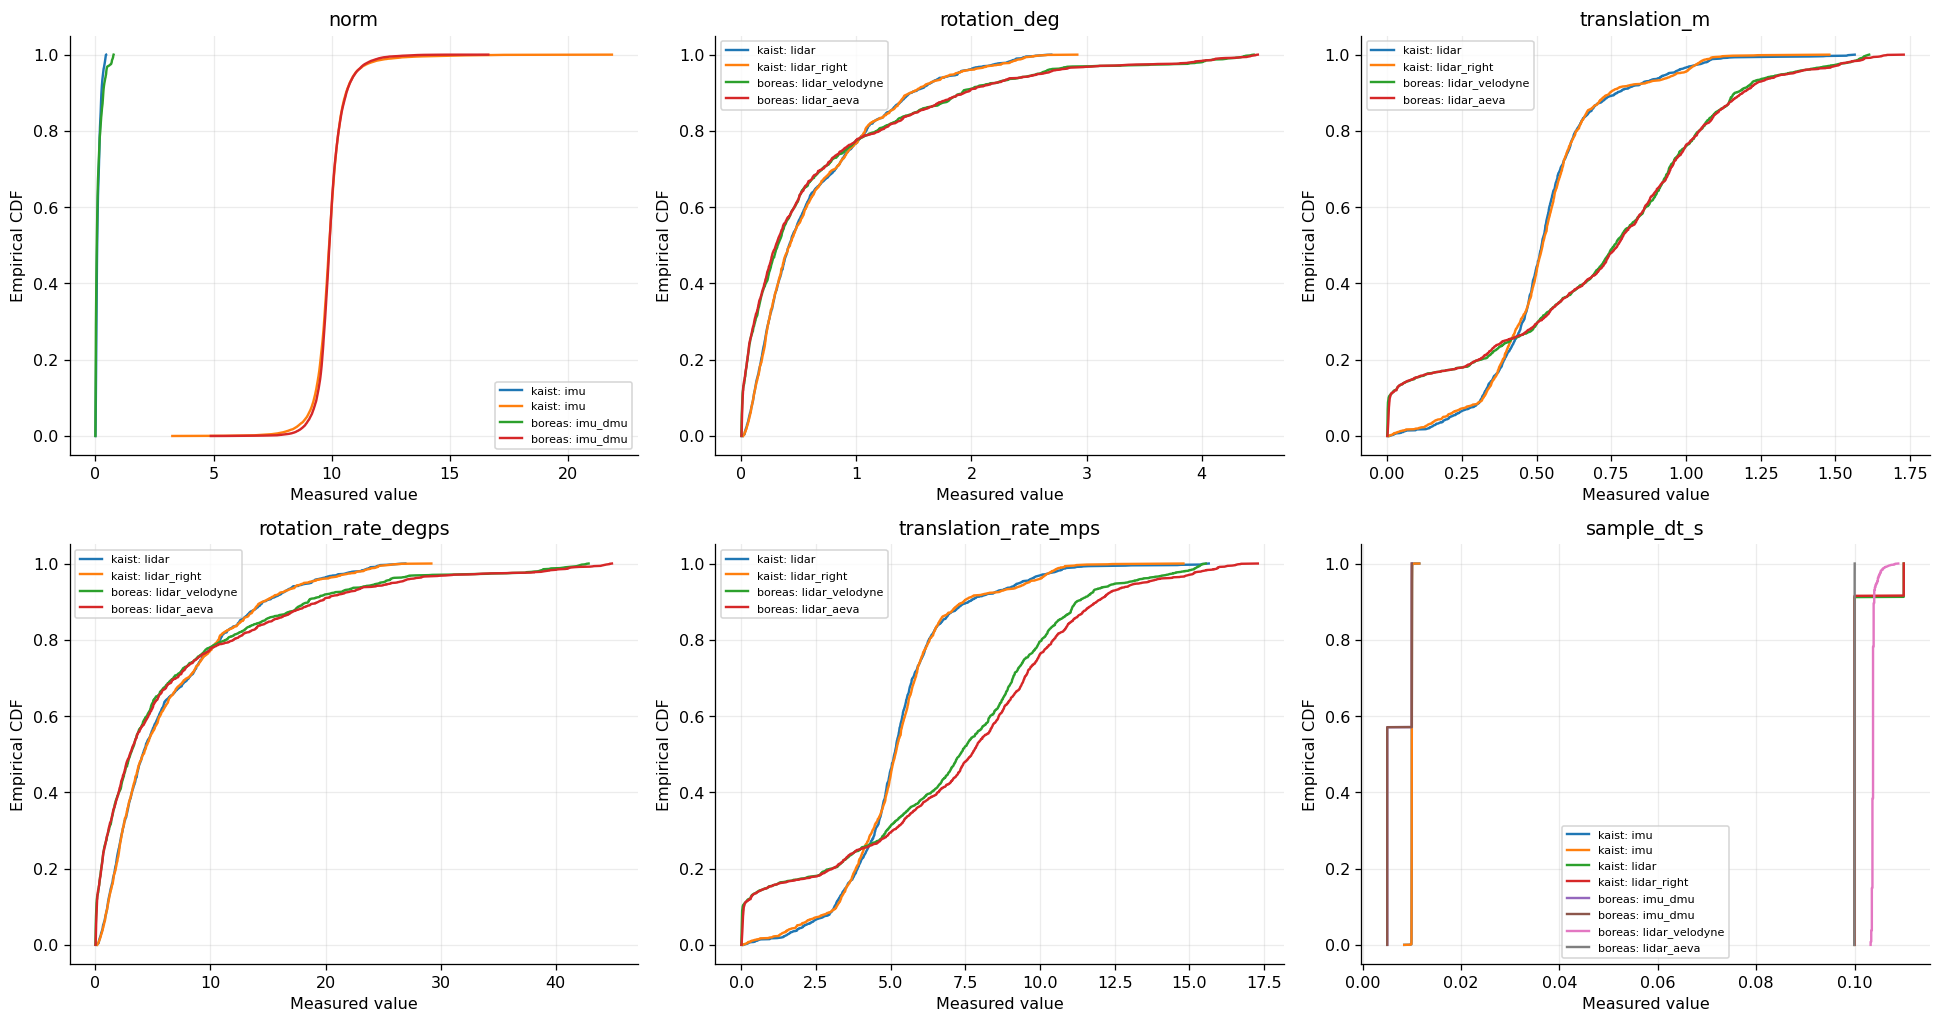

In [13]:
# Plot robust pooled distributions separately for every actual stream (no frame equality assumed).
feature_suffixes=("/norm","/rotation_deg","/translation_m","/rotation_rate_degps","/translation_rate_mps","/sample_dt_s")
fig,axs=plt.subplots(2,3,figsize=(17,9))
for ax,suffix in zip(axs.flat,feature_suffixes):
    any_line=False
    for domain, features in RAW_VALUES.items():
        for name, vals in features.items():
            if not name.endswith(suffix):continue
            finite=np.sort(vals[np.isfinite(vals)])
            if finite.size==0:continue
            finite=finite[np.linspace(0,len(finite)-1,min(len(finite),PLOT_MAX_POINTS),dtype=int)]
            ax.plot(finite,np.linspace(0,1,len(finite)),label=f"{domain}: {name.split('/')[0]}")
            any_line=True
    ax.set(title=suffix[1:],xlabel="Measured value",ylabel="Empirical CDF")
    if any_line:ax.legend(fontsize=7)
finish_plot(fig,"01_raw_feature_cdf.png")

### 6.1. Mounting-frame differences and directional IMU signals

Rotation and gravity-vector directions can shift dramatically between datasets, even if sensor motion *norms* look similar. The table reports nominal IMU-to-LiDAR frame orientation and descriptive acceleration/gyroscope axes. Acceleration means over moving windows are **not** treated as gravity estimates.

In [14]:
frame_rows=[]
for domain,windows in DOMAIN_WINDOWS.items():
    if domain=="kaist" and not KAIST_REFERENCE_READY:continue
    win=windows[0];groups=role_streams(win)
    for imu_key in calibration_keys_of_kind(win,"gyro"):
        for lidar_key in calibration_keys_of_kind(win,"lidar"):
            TI=win.current_calibration[imu_key].transform[0].detach().cpu().numpy()
            TL=win.current_calibration[lidar_key].transform[0].detach().cpu().numpy()
            TIL=np.linalg.solve(TI,TL)
            gyro=win.streams[groups[imu_key]["gyro"]].values[0].detach().cpu().numpy()
            accel=win.streams[groups[imu_key]["accel"]].values[0].detach().cpu().numpy()
            frame_rows.append(dict(domain=domain,imu=imu_key,lidar=lidar_key,
                nominal_imu_lidar_rotation_deg=np.rad2deg(Rot.from_matrix(TIL[:3,:3]).magnitude()),
                nominal_imu_lidar_baseline_m=np.linalg.norm(TIL[:3,3]),
                gyro_mean_xyz_radps=np.round(gyro.mean(axis=0),4),
                accel_mean_xyz_mps2=np.round(accel.mean(axis=0),3)))
frame_table=pd.DataFrame(frame_rows)
if not frame_table.empty:display(frame_table)


,domain,imu,lidar,nominal_imu_lidar_rotation_deg,nominal_imu_lidar_baseline_m,gyro_mean_xyz_radps,accel_mean_xyz_mps2
0,kaist,imu,lidar,139.388502,3.667038,"[-0.003, -0.0019, -0.0003]","[0.718, 0.168, 9.835]"
1,kaist,imu,lidar_right,139.240013,3.673863,"[-0.003, -0.0019, -0.0003]","[0.718, 0.168, 9.835]"
2,boreas,imu_dmu,lidar_velodyne,179.983686,0.280000,"[-1e-04, 0.0, -1e-04]","[-0.24, -0.249, -9.788]"
3,boreas,imu_dmu,lidar_aeva,179.937166,0.492450,"[-1e-04, 0.0, -1e-04]","[-0.24, -0.249, -9.788]"


## 7. Motion consistency: measured gyro vs independent LiDAR rotation, with clock-shift sweep

In [15]:
# This diagnostic is not a neural-network input and does not use reference LiDAR poses.
# Compare R_imu(t_i,t_j) to R_I_L @ R_lidar(i,j) @ R_I_L.T.
# LiDAR measurements may have scan-time / deskew biases, and the integration is first-order.
SHIFT_GRID_S=np.round(np.linspace(-0.2,0.2,17),4)
GYRO_INTEGRATION_STEP_S=0.01
MAX_CONSISTENCY_EDGES=200
MIN_GYRO_EDGE_DEG=0.10

def integrate_gyro(t,w,start,end,step_s=0.01):
    if start<t[0] or end>t[-1] or end<=start:return None
    segments=max(1,int(np.ceil((end-start)/step_s)))
    dt=(end-start)/segments
    ts=start+(np.arange(segments)+.5)*dt
    omega=np.column_stack([np.interp(ts,t,w[:,k]) for k in range(3)])
    answer=Rot.identity()
    for value in omega: answer=answer*Rot.from_rotvec(value*dt)
    return answer

def motion_consistency_rows(domain, windows):
    rows=[]
    if domain=="kaist" and not KAIST_REFERENCE_READY:return rows
    for wi, window in enumerate(windows[:min(len(windows),8)]):
        groups=role_streams(window)
        for i_key in calibration_keys_of_kind(window,"gyro"):
            for l_key in calibration_keys_of_kind(window,"lidar"):
                gn=groups[i_key]["gyro"];ln=groups[l_key]["lidar"]
                gyro=window.streams[gn];lidar=window.streams[ln]
                tg=gyro.timestamps[0].detach().cpu().numpy().astype(float)
                wg=gyro.values[0].detach().cpu().numpy().astype(float)
                t1=lidar.timestamps[0].detach().cpu().numpy().astype(float)
                t0=lidar.interval_start_timestamps[0].detach().cpu().numpy().astype(float)
                TL=lidar.values[0].detach().cpu().numpy().astype(float)
                Ti=window.current_calibration[i_key].transform[0].detach().cpu().numpy()
                Te=window.current_calibration[l_key].transform[0].detach().cpu().numpy()
                RIL=(np.linalg.solve(Ti,Te))[:3,:3]
                selected=np.linspace(0,len(TL)-1,min(len(TL),MAX_CONSISTENCY_EDGES),dtype=int)
                for shift in SHIFT_GRID_S:
                    diffs=[];angles=[];inverse_diffs=[]
                    for k in selected:
                        r=integrate_gyro(tg,wg,t0[k]+shift,t1[k]+shift,GYRO_INTEGRATION_STEP_S)
                        if r is None:continue
                        rl=Rot.from_matrix(RIL@TL[k,:3,:3]@RIL.T)
                        a=np.rad2deg(r.magnitude())
                        diffs.append(np.rad2deg((r.inv()*rl).magnitude()))
                        inverse_diffs.append(np.rad2deg((r.inv()*rl.inv()).magnitude()))
                        angles.append(a)
                    if not diffs:continue
                    diffs=np.asarray(diffs);angles=np.asarray(angles)
                    moving=angles>=MIN_GYRO_EDGE_DEG
                    rows.append(dict(domain=domain,window=wi,imu=i_key,lidar=l_key,shift_s=shift,
                                     n=len(diffs),moving_n=int(moving.sum()),
                                     median_error_deg=float(np.median(diffs[moving])) if moving.any() else np.nan,
                                     median_inverse_error_deg=float(np.median(np.asarray(inverse_diffs)[moving])) if moving.any() else np.nan,
                                     all_error_deg=float(np.median(diffs))))
    return rows

# For numerical consistency smoke test only, constant gyro integration must equal closed form.
_smoke_t=np.linspace(0,1,101);_smoke_w=np.tile([0.1,-0.2,0.3],(101,1))
assert np.allclose(integrate_gyro(_smoke_t,_smoke_w,.2,.8).as_matrix(),
                   Rot.from_rotvec(np.array([0.1,-0.2,0.3])*.6).as_matrix(),atol=1e-10)
consistency=pd.DataFrame()
if RUN_MOTION_CONSISTENCY:
    all_rows=[]
    for domain, windows in DOMAIN_WINDOWS.items():all_rows.extend(motion_consistency_rows(domain,windows))
    consistency=pd.DataFrame(all_rows)
    if not consistency.empty:
        display(consistency.groupby(["domain","imu","lidar","shift_s"],as_index=False)
                .agg(median_moving_deg=("median_error_deg","median"),
                     median_inverse_deg=("median_inverse_error_deg","median"),moving_n=("moving_n","sum"))
                .sort_values("median_moving_deg").groupby(["domain","imu","lidar"]).head(3))
        if SAVE_PLOTS:consistency.to_csv(OUT/"gyro_lidar_rotation_consistency.csv",index=False)

,domain,imu,lidar,shift_s,median_moving_deg,median_inverse_deg,moving_n
25,boreas,imu_dmu,lidar_velodyne,0.000,0.048554,1.494103,277
24,boreas,imu_dmu,lidar_velodyne,-0.025,0.062223,1.485470,278
26,boreas,imu_dmu,lidar_velodyne,0.025,0.071015,1.528093,276
10,boreas,imu_dmu,lidar_aeva,0.050,0.088312,1.350217,291
41,kaist,imu,lidar,-0.025,0.098130,0.840255,230
11,boreas,imu_dmu,lidar_aeva,0.075,0.101541,1.360332,290
58,kaist,imu,lidar_right,-0.025,0.106742,0.917674,225
40,kaist,imu,lidar,-0.050,0.108935,0.848081,224
57,kaist,imu,lidar_right,-0.050,0.110888,0.837074,227
59,kaist,imu,lidar_right,0.000,0.111641,0.825486,227


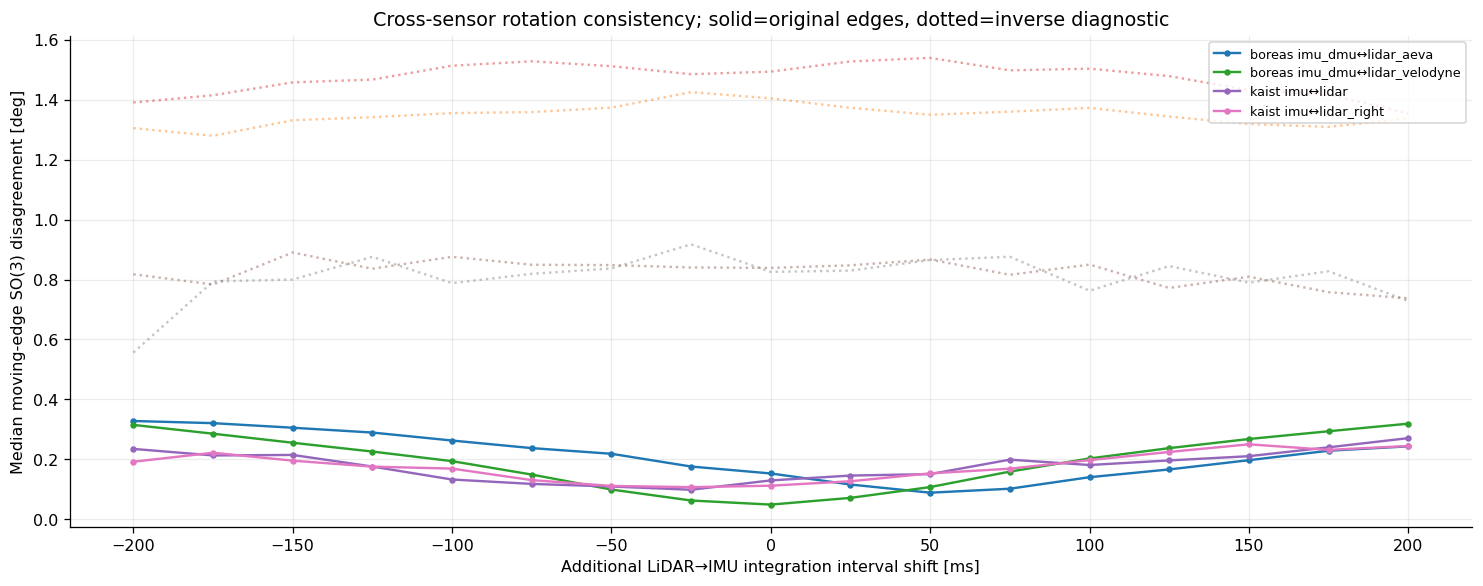

In [16]:
if not consistency.empty:
    g=consistency.groupby(["domain","imu","lidar","shift_s"],as_index=False).agg(
        forward=("median_error_deg","median"),inverse=("median_inverse_error_deg","median"))
    fig,ax=plt.subplots(figsize=(13,5.2))
    for (domain,imu,lidar),chunk in g.groupby(["domain","imu","lidar"]):
        ax.plot(chunk.shift_s*1000,chunk.forward,"-o",ms=3,label=f"{domain} {imu}↔{lidar}")
        ax.plot(chunk.shift_s*1000,chunk.inverse,":",alpha=.45)
    ax.set(xlabel="Additional LiDAR→IMU integration interval shift [ms]",
           ylabel="Median moving-edge SO(3) disagreement [deg]",
           title="Cross-sensor rotation consistency; solid=original edges, dotted=inverse diagnostic")
    ax.legend(fontsize=8)
    finish_plot(fig,"02_gyro_lidar_time_shift_sweep.png")

## 8. Frozen FM .11 and optional regression 2.26; token-domain statistics

In [17]:
model_config=PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8,d_model=128,n_heads=8,num_layers=12,
                                  dim_feedforward=512,dropout=0.0,num_summary_tokens=1,activation="gelu"),
    mlp=MLPConfig(hidden_dims=(256,128),output_dim=128,activation="gelu",dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8,dropout=0.0,calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0,hidden_dims=(128,64),activation="gelu",dropout=0.0))
flow_config=PooledCalibrationFlowConfig(backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_STEPS,method=FM_METHOD),
    freeze_backbone_initially=False)
fm=PooledCalibrationFlowModel(flow_config.backbone,**flow_config.model_kwargs()).to(DEVICE,dtype=MODEL_DTYPE)
checkpoint_path=FM_CHECKPOINT if FM_CHECKPOINT.is_absolute() else ROOT/FM_CHECKPOINT
fm_metadata=load_training_checkpoint(checkpoint_path,model=fm,map_location=DEVICE,restore_rng_state=False)
fm.eval().requires_grad_(False)
MODELS={"FM .11":fm}
if RUN_REGRESSION:
    regression=PooledCalibrationModel(model_config).to(DEVICE,dtype=MODEL_DTYPE)
    ckpt=REGRESSION_CHECKPOINT if REGRESSION_CHECKPOINT.is_absolute() else ROOT/REGRESSION_CHECKPOINT
    regression_metadata=load_training_checkpoint(ckpt,model=regression,map_location=DEVICE,restore_rng_state=False)
    regression.eval().requires_grad_(False)
    MODELS["Regression 2.26"]=regression
geometry_processor=GeometryProcessor()

def to_device(window):return window_batch_to(window,DEVICE,dtype=MODEL_DTYPE)

def tokenize_window(window,states):
    if set(states)!=set(window.current_calibration):raise ValueError("state/window calibration mismatch")
    canonical=geometry_processor(window.streams,window.metadata,states)
    keys=tuple(window.current_calibration)
    tokens=Tokenizer(measurement_dim=6,calibration_keys=keys)(canonical,observability=None)
    context={key:calibration_state_to_context(states[key]) for key in keys}
    if tokens.x.ndim!=3 or tokens.x.shape[-1]!=8 or not torch.isfinite(tokens.x).all():
        raise RuntimeError("Invalid/nonfinite canonical model tokens")
    return tokens,context

@torch.inference_mode()
def model_predict(model,window,states):
    tokens,ctx=tokenize_window(window,states)
    pred=model(tokens,ctx,num_steps=FM_STEPS,method=FM_METHOD) if isinstance(model,PooledCalibrationFlowModel) else model(tokens,ctx)
    if set(pred.predictions)!=set(states):raise RuntimeError("Incomplete calibration predictions")
    return pred

print("Model checkpoints loaded; frozen parameter counts:",
      {name:sum(p.numel() for p in model.parameters()) for name,model in MODELS.items()})

Model checkpoints loaded; frozen parameter counts: {'FM .11': 2555399}


,domain,token_feature,mean,std,median,p05,p95,p99
0,kaist,0,0.12178,0.51392,0.00349,-0.48191,1.02920,1.73848
1,kaist,1,0.09592,0.77982,0.00064,-0.95343,1.37373,2.89895
2,kaist,2,4.50513,4.89528,0.21765,-0.00572,10.33494,11.28679
3,kaist,3,0.03776,0.15502,0.00000,0.00000,0.50690,0.66568
4,kaist,4,-0.00010,0.00342,0.00000,-0.00028,0.00000,0.01052
5,kaist,5,0.00008,0.00245,0.00000,0.00000,0.00000,0.01006
6,kaist,6,2.50419,1.44160,2.50541,0.25783,4.74986,4.95002
7,kaist,7,0.63357,0.64051,1.00000,0.00000,2.00000,2.00000
8,boreas,0,-0.17836,0.79567,-0.00234,-1.43266,0.49903,1.39990
9,boreas,1,0.03817,0.50428,0.00042,-0.74026,0.93018,1.84049


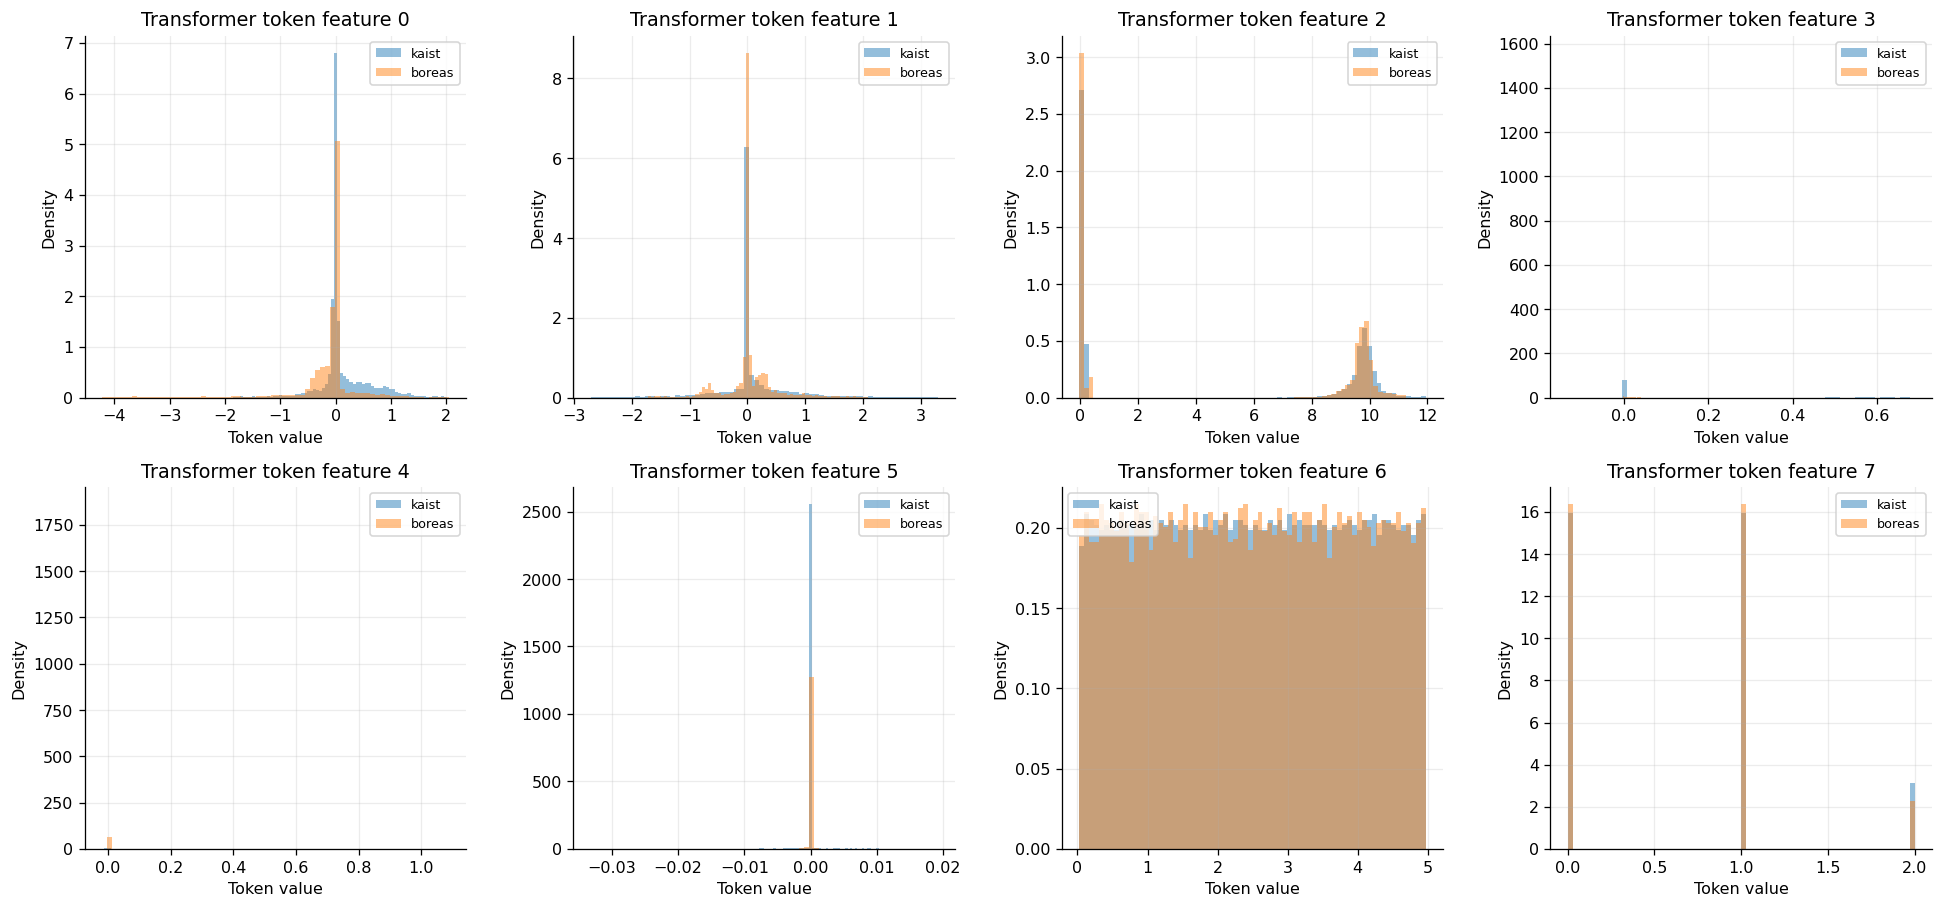

In [18]:
token_summary=[]
token_samples={}
if RUN_TOKEN_ANALYSIS:
    for domain,windows in DOMAIN_WINDOWS.items():
        if domain=="kaist" and not KAIST_REFERENCE_READY:
            print("SKIP KAIST token analysis: first configure the reference rig")
            continue
        chunks=[]
        for i in sorted({0,len(windows)//3,2*len(windows)//3,len(windows)-1}):
            window=to_device(windows[i])
            tokens,_=tokenize_window(window,window.current_calibration)
            chunks.append(tokens.x.detach().cpu().numpy().reshape(-1,8))
        arr=np.concatenate(chunks)
        arr=arr[np.linspace(0,len(arr)-1,min(len(arr),PLOT_MAX_POINTS),dtype=int)]
        token_samples[domain]=arr
        for j in range(8):
            token_summary.append(dict(domain=domain,token_feature=j,mean=np.mean(arr[:,j]),std=np.std(arr[:,j]),
                                      median=np.median(arr[:,j]),p05=np.percentile(arr[:,j],5),
                                      p95=np.percentile(arr[:,j],95),p99=np.percentile(arr[:,j],99)))
    if token_summary:
        token_table=pd.DataFrame(token_summary)
        display(token_table.round(5))
        if SAVE_PLOTS:token_table.to_csv(OUT/"canonical_token_statistics.csv",index=False)
        fig,axs=plt.subplots(2,4,figsize=(17,8))
        for j,ax in enumerate(axs.flat):
            for domain,arr in token_samples.items():
                v=arr[:,j]
                low,high=np.percentile(v,[.5,99.5])
                ax.hist(v[(v>=low)&(v<=high)],bins=70,alpha=.48,density=True,label=domain)
            ax.set(title=f"Transformer token feature {j}",xlabel="Token value",ylabel="Density")
            ax.legend(fontsize=8)
        finish_plot(fig,"03_pre_transformer_token_distributions.png")

## 9. Configurable in-place augmentation lab

**Edit `AUGMENT`**, rerun from this cell onward, and compare with `baseline`. Augmentations are applied to *copies* of loaded windows; cached CSVs and IMU files remain untouched. Each IMU and LiDAR stream is addressed by **modality**, so the code works on both datasets regardless of stream names or sensor count.

Two types of interventions:

- **Re-expression (physics-preserving):** `common_body_yaw_deg` left-multiplies every extrinsic by the same rotation. `lidar_sensor_frame_deg` changes the **LiDAR coordinate basis**, applying the corresponding conjugation to every relative pose and right-multiplying its extrinsic. `imu_sensor_frame_deg` similarly rotates measured gyro/accel vectors and IMU extrinsic. These should preserve physical relationships; large model changes indicate learned frame dependence.
- **Measurement-corruption or OOD stress tests:** bias/noise/scaling, edge inversion, decimation and timestamp changes. They probe robustness and input conventions; they are not necessarily physically plausible sensor augmentations. `lidar_rotation_scale` only modifies the rotational component and is not a complete motion model.

Noise is only introduced when explicitly configured and is deterministically seeded. **Never use perturbed measurement values as ground truth.** The initial calibration fault and the score are always derived from the appropriate nominal reference after any coordinate re-expression.

In [19]:
@dataclass(frozen=True)
class AugmentConfig:
    imu_gyro_gain: float=1.0
    imu_accel_gain: float=1.0
    imu_gyro_bias_radps: tuple=(0.0,0.0,0.0)
    imu_gyro_noise_std_radps: float=0.0
    imu_accel_noise_std_mps2: float=0.0
    imu_stride: int=1
    imu_timestamp_shift_s: float=0.0
    lidar_translation_gain: float=1.0
    lidar_rotation_scale: float=1.0
    lidar_rotation_bias_deg: tuple=(0.0,0.0,0.0)
    lidar_rotation_noise_std_deg: float=0.0
    lidar_translation_noise_std_m: float=0.0
    lidar_stride: int=1
    lidar_timestamp_shift_s: float=0.0
    invert_lidar_edges: bool=False
    common_body_yaw_deg: float=0.0
    lidar_sensor_frame_deg: tuple=(0.0,0.0,0.0)
    imu_sensor_frame_deg: tuple=(0.0,0.0,0.0)

AUGMENT=AugmentConfig()        # Change and re-evaluate; base control is always AugmentConfig()
AUGMENT_DOMAIN="boreas"      # "kaist", "boreas", or "both"
AUGMENT_ONLY_KEYS=()         # Optional exact calibration keys; () = all applicable sensors

BASELINE=AugmentConfig()

def _rotation_H(rotvec_deg):
    H=np.eye(4)
    H[:3,:3]=Rot.from_rotvec(np.deg2rad(np.asarray(rotvec_deg,dtype=float))).as_matrix()
    return H

def _rot_state(state,T):
    return CalibrationState(transform=T,time_offset=state.time_offset.clone())

def _replace_stream(stream,values,timestamps,starts,keep):
    new_values=torch.as_tensor(values,dtype=stream.values.dtype,device=stream.values.device).unsqueeze(0)
    new_t=torch.as_tensor(timestamps,dtype=stream.timestamps.dtype,device=stream.timestamps.device).unsqueeze(0)
    new_start=None if starts is None else torch.as_tensor(starts,dtype=stream.timestamps.dtype,device=stream.timestamps.device).unsqueeze(0)
    # Metadata must remain intact; update all length-indexed public fields if present.
    overrides={"values":new_values,"timestamps":new_t,"interval_start_timestamps":new_start}
    if getattr(stream,"sample_mask",None) is not None:
        overrides["sample_mask"]=torch.ones((1,len(keep)),dtype=stream.sample_mask.dtype,device=stream.sample_mask.device)
    return replace(stream,**{k:v for k,v in overrides.items() if any(f.name==k for f in dataclasses.fields(stream))})

def augment_window(window,cfg:AugmentConfig,*,window_index=0,domain="unknown",only_keys=()):
    if cfg.imu_stride<1 or cfg.lidar_stride<1:raise ValueError("Strides must be >=1")
    streams={}
    states={key:CalibrationState(transform=value.transform.clone(),time_offset=value.time_offset.clone())
            for key,value in window.current_calibration.items()}
    rng_cache={}
    H_body=_rotation_H((0.0,0.0,cfg.common_body_yaw_deg))
    H_lidar=_rotation_H(cfg.lidar_sensor_frame_deg)
    H_imu=_rotation_H(cfg.imu_sensor_frame_deg)
    # Common frame change is a single left multiplication for every sensor, including unaffected ones.
    for key,state in list(states.items()):
        T=state.transform.clone()
        T[:]=torch.as_tensor(H_body,device=T.device,dtype=T.dtype)@T
        states[key]=_rot_state(state,T)
    target=set(only_keys) if only_keys else set(states)
    for name,stream in window.streams.items():
        role=kind_of(window.metadata[name]);key=window.metadata[name].calibration_key
        v=stream.values[0].detach().cpu().numpy().copy()
        tt=stream.timestamps[0].detach().cpu().numpy().astype(float).copy()
        st=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps[0].detach().cpu().numpy().astype(float).copy()
        if key not in target:
            streams[name]=stream
            continue
        seed=(RANDOM_SEED+window_index*10007+zlib.crc32(f"{domain}/{name}".encode()))%(2**32)
        rng=np.random.default_rng(seed)
        if role in ("gyro","accel"):
            # Rotate both IMU modalities in the same sensor-local basis.
            v=v@H_imu[:3,:3]  # v_new = R_old_new.T v_old (row vectors)
            if role=="gyro":
                v=v*cfg.imu_gyro_gain+np.asarray(cfg.imu_gyro_bias_radps,dtype=float)
                if cfg.imu_gyro_noise_std_radps:v+=rng.normal(0,cfg.imu_gyro_noise_std_radps,v.shape)
            else:
                v=v*cfg.imu_accel_gain
                if cfg.imu_accel_noise_std_mps2:v+=rng.normal(0,cfg.imu_accel_noise_std_mps2,v.shape)
            tt+=cfg.imu_timestamp_shift_s
            take=np.arange(0,len(v),cfg.imu_stride)
            # Shared IMU extrinsic updated below once per calibration key.
        elif role=="lidar":
            v=np.linalg.solve(H_lidar,v@H_lidar)
            v[:,:3,3]*=cfg.lidar_translation_gain
            if cfg.lidar_rotation_scale!=1.0:
                v[:,:3,:3]=Rot.from_rotvec(Rot.from_matrix(v[:,:3,:3]).as_rotvec()*cfg.lidar_rotation_scale).as_matrix()
            H_bias=Rot.from_rotvec(np.deg2rad(cfg.lidar_rotation_bias_deg)).as_matrix()
            v[:,:3,:3]=H_bias@v[:,:3,:3]
            if cfg.lidar_rotation_noise_std_deg:
                jitter=Rot.from_rotvec(np.deg2rad(rng.normal(0,cfg.lidar_rotation_noise_std_deg,(len(v),3)))).as_matrix()
                v[:,:3,:3]=jitter@v[:,:3,:3]
            if cfg.lidar_translation_noise_std_m:
                v[:,:3,3]+=rng.normal(0,cfg.lidar_translation_noise_std_m,(len(v),3))
            if cfg.invert_lidar_edges:v=np.linalg.inv(v)
            tt+=cfg.lidar_timestamp_shift_s
            st+=cfg.lidar_timestamp_shift_s
            take=np.arange(0,len(v),cfg.lidar_stride)
        else:raise ValueError(f"Unknown measurement role for {name}: {role}")
        streams[name]=_replace_stream(stream,v[take],tt[take],None if st is None else st[take],take)
    # Right-change the nominal extrinsics only once per physical sensor (one gyro + accel pair).
    for key in target:
        stream_roles=role_streams(window)[key]
        H=H_imu if "gyro" in stream_roles else H_lidar
        T=states[key].transform@torch.as_tensor(H,device=states[key].transform.device,dtype=states[key].transform.dtype)
        states[key]=_rot_state(states[key],T)
    result=replace(window,streams=streams,current_calibration=states)
    valid_window(result)
    return result

### 9.1. Mathematical self-tests of re-expression and no-op

In [20]:
# No synthetic inputs are used in the model evaluation; here we only test exact transform algebra.
probe=next(iter(DOMAIN_WINDOWS.values()))[0]
control=augment_window(probe,BASELINE,domain="test")
for name in probe.streams:
    torch.testing.assert_close(probe.streams[name].values,control.streams[name].values,atol=1e-6,rtol=1e-6)
for key in probe.current_calibration:
    torch.testing.assert_close(probe.current_calibration[key].transform,control.current_calibration[key].transform,atol=1e-6,rtol=1e-6)
# Re-expressed relative LiDAR rotations and mounting rotations must give identical body-frame increments.
rot_cfg=AugmentConfig(lidar_sensor_frame_deg=(12.,-17.,21.),imu_sensor_frame_deg=(8.,3.,-14.),common_body_yaw_deg=34.)
reframed=augment_window(probe,rot_cfg,domain="test")
for key,groups in role_streams(probe).items():
    if "lidar" not in groups:continue
    name=groups["lidar"]
    old=probe.streams[name].values[0].numpy()
    new=reframed.streams[name].values[0].numpy()
    Rold=probe.current_calibration[key].transform[0,:3,:3].numpy()
    Rnew=reframed.current_calibration[key].transform[0,:3,:3].numpy()
    H=Rot.from_euler("z",34,degrees=True).as_matrix()
    old_body=Rold@old[:,:3,:3]@Rold.T
    new_body=Rnew@new[:,:3,:3]@Rnew.T
    np.testing.assert_allclose(new_body,H@old_body@H.T,atol=1e-5)
print("No-op, SE(3) sensor re-expression, and common body-frame invariants: PASS")

No-op, SE(3) sensor re-expression, and common body-frame invariants: PASS


## 10. Raw and token distribution before/after augmentation

In [21]:
# Useful even if you do not run any frozen FM inference.
augmented_feature_rows=[]
for domain,windows in DOMAIN_WINDOWS.items():
    for index in sorted({0,len(windows)//2,len(windows)-1}):
        source=windows[index]
        run_cfg=AUGMENT if (AUGMENT_DOMAIN in ("both",domain)) else BASELINE
        altered=augment_window(source,run_cfg,window_index=index,domain=domain,only_keys=AUGMENT_ONLY_KEYS)
        for status,w in (("baseline",source),("augmented",altered)):
            for feature,values in raw_feature_arrays(w).items():
                augmented_feature_rows.append(dict(domain=domain,variant=status,window=index,feature=feature,
                                                   median=np.median(values),p95=np.percentile(values,95)))
augmented_features=pd.DataFrame(augmented_feature_rows)
changes=augmented_features.pivot_table(index=["domain","window","feature"],columns="variant",values="p95").dropna()
changes["difference"]=changes["augmented"]-changes["baseline"]
display(changes[changes.difference.abs()>1e-7].round(5).head(60))

,,variant,augmented,baseline,difference
domain,window,feature,,,


## 11. FM fault injection, one-window correction, and chronological rollouts

In [22]:
def states_clone(states):
    return {key:CalibrationState(transform=state.transform.clone(),time_offset=state.time_offset.clone())
            for key,state in states.items()}

def so3_err(Ta,Tb):
    R=Tb[:,:3,:3]@Ta[:,:3,:3].transpose(-1,-2)
    skew=torch.stack((R[:,2,1]-R[:,1,2],R[:,0,2]-R[:,2,0],R[:,1,0]-R[:,0,1]),dim=1)
    return torch.rad2deg(torch.atan2(.5*torch.linalg.vector_norm(skew,dim=1),
                                     .5*(torch.diagonal(R,dim1=-2,dim2=-1).sum(dim=1)-1)))

def inject_fault(reference,key,angle_deg,axis):
    result=states_clone(reference)
    direction=np.eye(3)[axis] if isinstance(axis,(int,np.integer)) else np.asarray(axis,dtype=float)
    direction=direction/np.linalg.norm(direction)
    rotvec=torch.as_tensor(direction,dtype=reference[key].transform.dtype,device=reference[key].transform.device).reshape(1,3)*np.deg2rad(float(angle_deg))
    T=result[key].transform.clone()
    T[:,:3,:3]=so3_exp(rotvec)@T[:,:3,:3]
    result[key]=CalibrationState(transform=T,time_offset=result[key].time_offset)
    assert np.isclose(float(so3_err(T,reference[key].transform).item()),float(angle_deg),atol=.05)
    return result

def update_one(states,pred,key):
    result=states_clone(states)
    delta=pred.predictions[key].delta_xi[:,:3]*ROLL_ROTATION_GAIN
    if MAX_ROTATION_STEP_DEG is not None:
        cap=np.deg2rad(MAX_ROTATION_STEP_DEG)
        delta=delta*(cap/delta.norm(dim=1,keepdim=True).clamp_min(1e-12)).clamp(max=1.0)
    T=states[key].transform.clone()
    T[:,:3,:3]=so3_exp(delta)@T[:,:3,:3]
    result[key]=CalibrationState(transform=T,time_offset=states[key].time_offset.clone())
    return result

def augmented_domain_window(domain,index,cfg):
    w=DOMAIN_WINDOWS[domain][index]
    # Never use the temporary identity KAIST rig to produce apparent calibration scores.
    if domain=="kaist" and REQUIRE_VALID_KAIST_RIG_FOR_FM and not KAIST_REFERENCE_READY:
        raise ValueError("FM on KAIST requires a genuine KAIST reference rig. Configure KAIST_RIG_JSON.")
    return to_device(augment_window(w,cfg,window_index=index,domain=domain,only_keys=AUGMENT_ONLY_KEYS))

@torch.inference_mode()
def score_one_window(domain,model,key,angle,axis,index,cfg):
    window=augmented_domain_window(domain,index,cfg)
    reference=window.current_calibration
    if key not in reference:raise KeyError((domain,key))
    # Preserve the same *physical* injected rotation when the common body frame is re-expressed.
    direction=Rot.from_euler("z",cfg.common_body_yaw_deg,degrees=True).apply(np.eye(3)[axis])
    initial=inject_fault(reference,key,angle,direction)
    pred=model_predict(model,window,initial)
    final=update_one(initial,pred,key)
    return dict(domain=domain,window=index,sensor=key,model=next((name for name,m in MODELS.items() if m is model),"model"),
                initial_angle_deg=float(angle),axis="xyz"[axis],
                final_error_deg=float(so3_err(final[key].transform,reference[key].transform).item()),
                improvement_deg=float(angle)-float(so3_err(final[key].transform,reference[key].transform).item()),
                predicted_step_deg=float(torch.rad2deg(pred.predictions[key].delta_xi[:,:3].norm(dim=-1)).item()))

DOMAIN_KEYS={domain:list(windows[0].current_calibration) for domain,windows in DOMAIN_WINDOWS.items()}
DOMAIN_FAULT_KEYS={domain:calibration_keys_of_kind(windows[0],"lidar") for domain,windows in DOMAIN_WINDOWS.items()}
print("LiDAR fault targets:",DOMAIN_FAULT_KEYS)

LiDAR fault targets: {'kaist': ('lidar', 'lidar_right'), 'boreas': ('lidar_velodyne', 'lidar_aeva')}


In [23]:
one_step=[]
if RUN_ONE_STEP:
    for domain,windows in DOMAIN_WINDOWS.items():
        if domain=="kaist" and not KAIST_REFERENCE_READY:
            print("SKIP KAIST FM: reference extrinsics not configured");continue
        indices=sorted({min(i,len(windows)-1) for i in EVALUATION_WINDOWS})
        cfg=AUGMENT if AUGMENT_DOMAIN in ("both",domain) else BASELINE
        jobs=[(domain,key,angle,axis,index,label,model) for key in DOMAIN_FAULT_KEYS[domain]
              for angle in FAULT_ANGLES_DEG for axis in (FAULT_AXES if angle else (0,))
              for index in indices for label,model in MODELS.items()]
        for _,key,angle,axis,index,label,model in tqdm(jobs,desc=f"One-step FM {domain}"):
            row=score_one_window(domain,model,key,angle,axis,index,cfg)
            row["condition"]="edited" if cfg!=BASELINE else "baseline"
            one_step.append(row)
    one_step=pd.DataFrame(one_step)
    if not one_step.empty:
        summary=one_step.groupby(["domain","sensor","model","initial_angle_deg"],as_index=False).agg(
            median_final_deg=("final_error_deg","median"),median_improvement_deg=("improvement_deg","median"),
            improved_fraction=("improvement_deg",lambda s:(s>0).mean()),cases=("improvement_deg","size"))
        display(summary.round(3))
        if SAVE_PLOTS:one_step.to_csv(OUT/"04_one_step_augmentation.csv",index=False)

One-step FM kaist:   0%|          | 0/96 [00:00<?, ?it/s]

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


One-step FM boreas:   0%|          | 0/96 [00:00<?, ?it/s]

,domain,sensor,model,initial_angle_deg,median_final_deg,median_improvement_deg,improved_fraction,cases
0,boreas,lidar_aeva,FM .11,0.0,1.696,-1.696,0.000,3
1,boreas,lidar_aeva,FM .11,15.0,14.385,0.615,0.778,9
2,boreas,lidar_aeva,FM .11,45.0,44.530,0.470,0.667,9
3,boreas,lidar_aeva,FM .11,90.0,89.306,0.694,0.556,9
4,boreas,lidar_aeva,FM .11,130.0,130.918,-0.918,0.333,9
5,boreas,lidar_aeva,FM .11,170.0,170.424,-0.424,0.333,9
6,boreas,lidar_velodyne,FM .11,0.0,1.650,-1.650,0.000,3
7,boreas,lidar_velodyne,FM .11,15.0,13.854,1.146,0.667,9
8,boreas,lidar_velodyne,FM .11,45.0,43.820,1.180,0.667,9
9,boreas,lidar_velodyne,FM .11,90.0,89.049,0.951,0.667,9


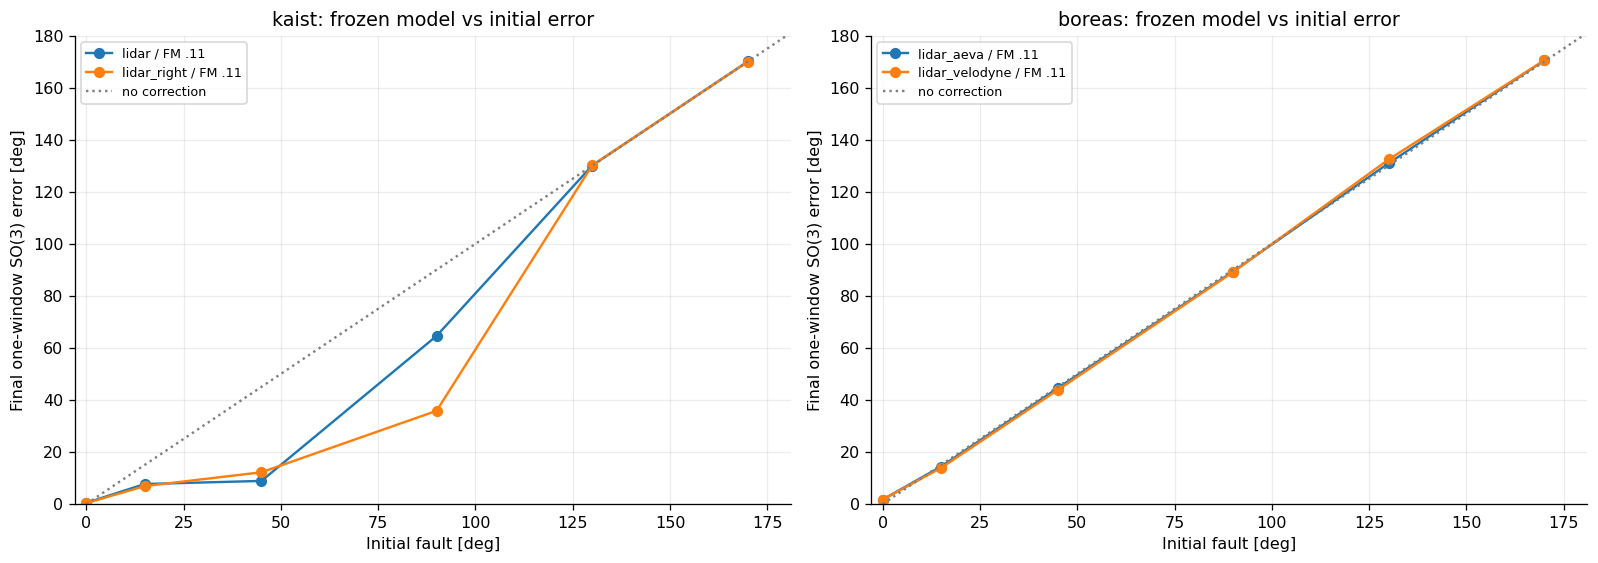

In [24]:
if isinstance(one_step,pd.DataFrame) and not one_step.empty:
    fig,axs=plt.subplots(1,len(one_step.domain.unique()),figsize=(7*len(one_step.domain.unique()),5),squeeze=False)
    for ax,domain in zip(axs.flat,one_step.domain.unique()):
        sub=one_step[one_step.domain==domain]
        for (sensor,model),group in sub.groupby(["sensor","model"]):
            g=group.groupby("initial_angle_deg",as_index=False).final_error_deg.median()
            ax.plot(g.initial_angle_deg,g.final_error_deg,"-o",label=f"{sensor} / {model}")
        ax.plot([0,180],[0,180],":",c="gray",label="no correction")
        ax.set(title=f"{domain}: frozen model vs initial error",xlabel="Initial fault [deg]",
               ylabel="Final one-window SO(3) error [deg]",xlim=(-3,181),ylim=(0,180))
        ax.legend(fontsize=8)
    finish_plot(fig,"05_one_window_fm_recovery_vs_initial_angle.png")

### 11.0. Motion-conditioned FM sensitivity

A model might fail because Boreas contains different excitation levels, rather than because its sensor labels changed. These plots associate a window's measured gyroscope and LiDAR motion with its **frozen-model one-step correction**. This is descriptive and does not use ground truth as an input.

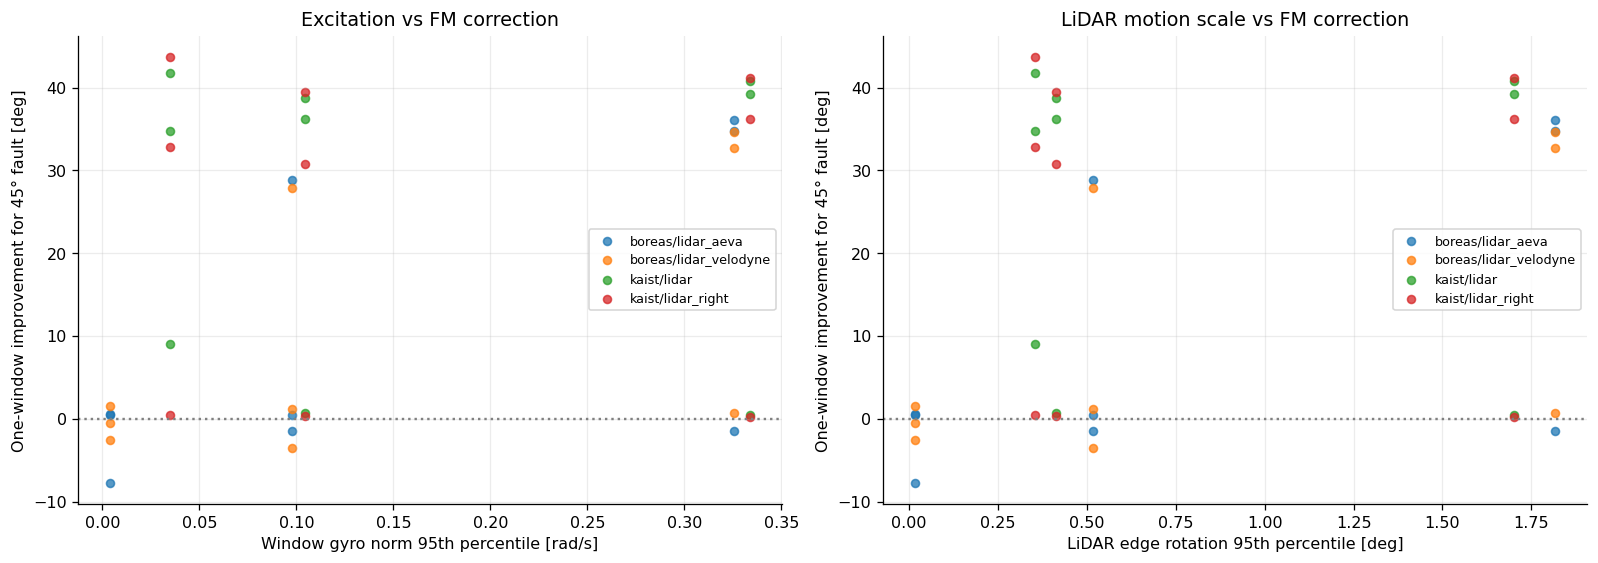

In [25]:
if isinstance(one_step,pd.DataFrame) and not one_step.empty:
    motion_rows=[]
    for domain,windows in DOMAIN_WINDOWS.items():
        for i,w in enumerate(windows):
            features=raw_feature_arrays(w)
            gyro_norms=[v for k,v in features.items() if k.endswith("/gyro/norm")]
            lidar_norms=[v for k,v in features.items() if k.endswith("/lidar/rotation_deg")]
            if not gyro_norms or not lidar_norms:continue
            motion_rows.append(dict(domain=domain,window=i,
                gyro_norm_p95_radps=float(np.median([np.percentile(x,95) for x in gyro_norms])),
                lidar_edge_rotation_p95_deg=float(np.median([np.percentile(x,95) for x in lidar_norms]))))
    motion_table=pd.DataFrame(motion_rows)
    pairs=one_step.merge(motion_table,on=["domain","window"],validate="many_to_one")
    focus=pairs[(pairs.initial_angle_deg==45.)]
    fig,axs=plt.subplots(1,2,figsize=(14,5))
    for (domain,sensor),part in focus.groupby(["domain","sensor"]):
        axs[0].scatter(part.gyro_norm_p95_radps,part.improvement_deg,s=25,alpha=.75,label=f"{domain}/{sensor}")
        axs[1].scatter(part.lidar_edge_rotation_p95_deg,part.improvement_deg,s=25,alpha=.75,label=f"{domain}/{sensor}")
    for ax in axs:
        ax.axhline(0,color="gray",linestyle=":")
        ax.set(ylabel="One-window improvement for 45° fault [deg]")
        ax.legend(fontsize=8)
    axs[0].set(xlabel="Window gyro norm 95th percentile [rad/s]",title="Excitation vs FM correction")
    axs[1].set(xlabel="LiDAR edge rotation 95th percentile [deg]",title="LiDAR motion scale vs FM correction")
    finish_plot(fig,"05b_motion_conditioned_fm_response.png")
    if SAVE_PLOTS:pairs.to_csv(OUT/"05b_fm_response_by_motion.csv",index=False)


### 11.1. Chronological rollouts: error vs time (without reinitialization)

In [26]:
@torch.inference_mode()
def run_rollout(domain,key,angle,axis,model,cfg,start=0,count=None):
    windows=DOMAIN_WINDOWS[domain]
    end=min(len(windows),start+(count or ROLLOUT_WINDOW_COUNT))
    indices=list(range(start,end))
    if len(indices)<2:raise ValueError("Need at least two consecutive physical windows")
    if domain=="kaist" and not KAIST_ASSUME_CONSECUTIVE_VALID_WINDOWS:
        raise ValueError("KAIST sequence-window chronology has not been verified; set KAIST_ASSUME_CONSECUTIVE_VALID_WINDOWS=True only after checking native window-start metadata")
    times=DOMAIN_TIMES[domain][indices]
    if len(times)>1 and np.any(np.diff(times)>WINDOW_STRIDE_S+1e-4):
        raise ValueError("Non-consecutive windows cannot be stitched into rollout")
    first=augmented_domain_window(domain,indices[0],cfg)
    truth=first.current_calibration
    direction=Rot.from_euler("z",cfg.common_body_yaw_deg,degrees=True).apply(np.eye(3)[axis])
    state=inject_fault(truth,key,angle,direction)
    results=[]
    for step,index in enumerate(indices):
        results.append(dict(domain=domain,sensor=key,initial_angle_deg=float(angle),axis="xyz"[axis],step=step,
                            elapsed_s=float(DOMAIN_TIMES[domain][index]-DOMAIN_TIMES[domain][indices[0]]),
                            error_deg=float(so3_err(state[key].transform,truth[key].transform).item())))
        window=augmented_domain_window(domain,index,cfg)
        # Augment-config frame changes must be constant across every window in the rollout.
        for k in truth:
            torch.testing.assert_close(window.current_calibration[k].transform,truth[k].transform,atol=2e-5,rtol=2e-5)
        pred=model_predict(model,window,state)
        state=update_one(state,pred,key)
    results.append(dict(domain=domain,sensor=key,initial_angle_deg=float(angle),axis="xyz"[axis],step=len(indices),
                        elapsed_s=float(times[-1]-times[0]+WINDOW_DURATION_S),
                        error_deg=float(so3_err(state[key].transform,truth[key].transform).item())))
    return results

rollout_rows=[]
if RUN_ROLLOUTS:
    for domain in DOMAIN_WINDOWS:
        if domain=="kaist" and (not KAIST_REFERENCE_READY or not KAIST_ASSUME_CONSECUTIVE_VALID_WINDOWS):
            print("SKIP KAIST chronological rollout: reference rig and consecutive timestamps need verification")
            continue
        cfg=AUGMENT if AUGMENT_DOMAIN in ("both",domain) else BASELINE
        cases=[(key,angle,axis,label,model) for key in DOMAIN_FAULT_KEYS[domain]
               for angle in FOCUS_FAULT_ANGLES_DEG for axis in (0 if angle==0 else FOCUS_FAULT_AXIS,)
               for label,model in MODELS.items()]
        for key,angle,axis,label,model in tqdm(cases,desc=f"Chronological {domain}"):
            for row in run_rollout(domain,key,angle,axis,model,cfg):
                row.update(model=label,condition="edited" if cfg!=BASELINE else "baseline")
                rollout_rows.append(row)
    rollouts=pd.DataFrame(rollout_rows)
    if not rollouts.empty:
        display(rollouts[rollouts.step==rollouts.step.max()].round(3))
        if SAVE_PLOTS:rollouts.to_csv(OUT/"06_fm_chronological_rollouts.csv",index=False)

SKIP KAIST chronological rollout: reference rig and consecutive timestamps need verification


Chronological boreas:   0%|          | 0/6 [00:00<?, ?it/s]

,domain,sensor,initial_angle_deg,axis,step,elapsed_s,error_deg,model,condition
15,boreas,lidar_velodyne,0.0,x,15,75.0,5.534,FM .11,baseline
31,boreas,lidar_velodyne,45.0,z,15,75.0,7.689,FM .11,baseline
47,boreas,lidar_velodyne,130.0,z,15,75.0,30.272,FM .11,baseline
63,boreas,lidar_aeva,0.0,x,15,75.0,4.366,FM .11,baseline
79,boreas,lidar_aeva,45.0,z,15,75.0,7.788,FM .11,baseline
95,boreas,lidar_aeva,130.0,z,15,75.0,40.616,FM .11,baseline


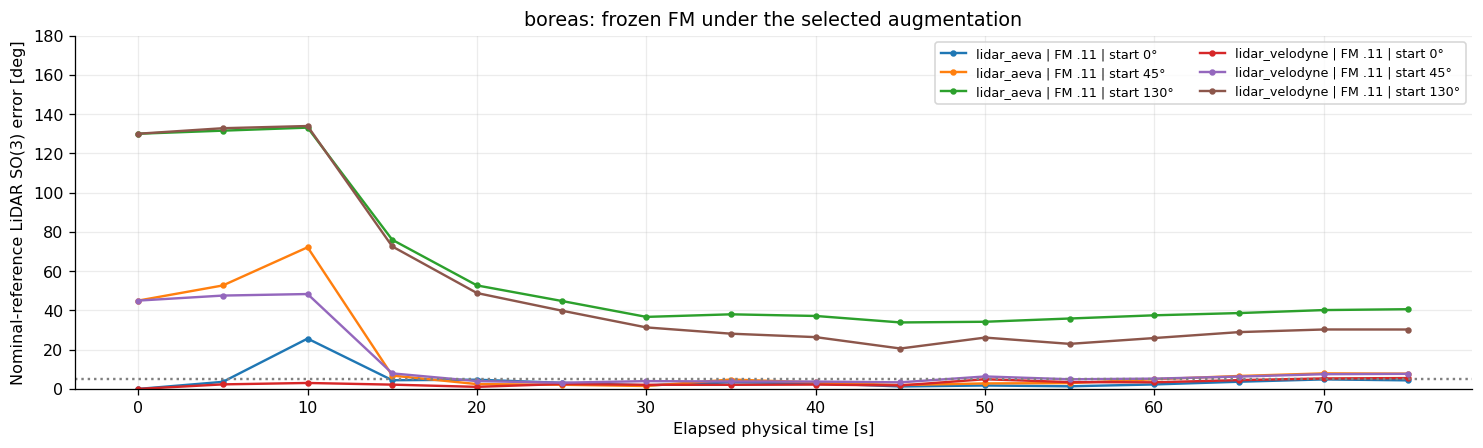

In [27]:
if rollout_rows:
    df=pd.DataFrame(rollout_rows)
    domains=df.domain.unique()
    fig,axs=plt.subplots(len(domains),1,figsize=(13,4*len(domains)),squeeze=False)
    for ax,domain in zip(axs.flat,domains):
        for (sensor,angle,model),group in df[df.domain==domain].groupby(["sensor","initial_angle_deg","model"]):
            ax.plot(group.elapsed_s,group.error_deg,marker=".",label=f"{sensor} | {model} | start {angle:g}°")
        ax.axhline(ROLLOUT_CONVERGENCE_DEG,ls=":",c="gray")
        ax.set(title=f"{domain}: frozen FM under the selected augmentation",xlabel="Elapsed physical time [s]",
               ylabel="Nominal-reference LiDAR SO(3) error [deg]",ylim=(0,180))
        ax.legend(fontsize=8,ncol=2)
    finish_plot(fig,"06_fm_lidar_error_vs_time.png")

## 12. Paired hypothesis sweep: break KAIST / rescue Boreas

All variants below run through **exactly the same model, physical windows, injected angles and calibration references**. Each row is paired to its own domain's baseline. The notebook never overwrites baseline input data. By default this is a **small one-window ablation**; once a candidate is promising, assign it to `AUGMENT` and run the longer chronological rollout above.

Interpretation: positive `Δ final error` means the intervention harmed the FM model; negative means improvement. A result that improves only one artificial fault angle, but worsens 0° stability, is not a robust fix. Sensor-frame changes here adjust both the LiDAR measurement and nominal extrinsic, unlike the `invert_edges` deliberately incorrect-convention control.

In [28]:
# Extend this dictionary in-place to try your next hypothesis with no code changes elsewhere.
ABLATIONS={
    "baseline":BASELINE,
    "lidar_time_minus_60ms":AugmentConfig(lidar_timestamp_shift_s=-0.060),
    "lidar_time_plus_60ms":AugmentConfig(lidar_timestamp_shift_s=+0.060),
    "lidar_rot_gain_0.7":AugmentConfig(lidar_rotation_scale=0.7),
    "lidar_rot_gain_1.3":AugmentConfig(lidar_rotation_scale=1.3),
    "lidar_rot_bias_z_0.05deg_per_edge":AugmentConfig(lidar_rotation_bias_deg=(0,0,0.05)),
    "lidar_inverted_edges_control":AugmentConfig(invert_lidar_edges=True),
    "lidar_sensor_frame_yaw_90deg":AugmentConfig(lidar_sensor_frame_deg=(0,0,90)),
    "body_frame_yaw_90deg":AugmentConfig(common_body_yaw_deg=90),
    "imu_gyro_gain_1.05":AugmentConfig(imu_gyro_gain=1.05),
    "lidar_stride_2":AugmentConfig(lidar_stride=2),
}
GRID_VARIANTS=("baseline","lidar_time_minus_60ms","lidar_time_plus_60ms",
               "lidar_rot_gain_0.7","lidar_rot_gain_1.3",
               "lidar_sensor_frame_yaw_90deg","body_frame_yaw_90deg")
GRID_ANGLES_DEG=(0.0,45.0)
GRID_AXES=(2,)
GRID_WINDOWS=(0,5,10)
GRID_SENSOR_KIND="lidar"                      # "lidar" or "imu"
GRID_MAX_MODELS=1                             # FM first; increase to include regression

In [29]:
grid_rows=[]
if RUN_ABLATION_GRID:
    for domain,windows in DOMAIN_WINDOWS.items():
        if domain=="kaist" and not KAIST_REFERENCE_READY:continue
        keys=calibration_keys_of_kind(windows[0],GRID_SENSOR_KIND)
        indices=sorted({min(x,len(windows)-1) for x in GRID_WINDOWS})
        jobs=[(variant,key,angle,axis,index,label,model) for variant in GRID_VARIANTS
              for key in keys for angle in GRID_ANGLES_DEG for axis in (GRID_AXES if angle else (0,))
              for index in indices for label,model in list(MODELS.items())[:GRID_MAX_MODELS]]
        for variant,key,angle,axis,index,label,model in tqdm(jobs,desc=f"Ablation sweep {domain}"):
            cfg=ABLATIONS[variant]
            # Grid ignores AUGMENT so baseline and each variant remain truly independent.
            row=score_one_window(domain,model,key,angle,axis,index,cfg)
            row["variant"]=variant
            grid_rows.append(row)
    grid=pd.DataFrame(grid_rows)
    if not grid.empty:
        base=grid[grid.variant=="baseline"].rename(columns={"final_error_deg":"baseline_final_deg"})
        joined=grid.merge(base[["domain","sensor","model","window","initial_angle_deg","axis","baseline_final_deg"]],
                          on=["domain","sensor","model","window","initial_angle_deg","axis"],validate="many_to_one")
        joined["delta_final_deg"]=joined.final_error_deg-joined.baseline_final_deg
        result=joined.groupby(["domain","sensor","model","variant","initial_angle_deg"],as_index=False).agg(
            baseline_deg=("baseline_final_deg","median"),final_deg=("final_error_deg","median"),
            median_change_deg=("delta_final_deg","median"),
            degraded_fraction=("delta_final_deg",lambda s:(s>0).mean()),cases=("delta_final_deg","size"))
        display(result.sort_values(["domain","sensor","initial_angle_deg","median_change_deg"]).round(3))
        if SAVE_PLOTS:
            joined.to_csv(OUT/"07_hypothesis_paired_cases.csv",index=False)
            result.to_csv(OUT/"07_hypothesis_grid_summary.csv",index=False)

Ablation sweep kaist:   0%|          | 0/84 [00:00<?, ?it/s]

Ablation sweep boreas:   0%|          | 0/84 [00:00<?, ?it/s]

,domain,sensor,model,variant,initial_angle_deg,baseline_deg,final_deg,median_change_deg,degraded_fraction,cases
12,boreas,lidar_aeva,FM .11,lidar_time_plus_60ms,0.0,1.696,1.267,-0.218,0.333,3
2,boreas,lidar_aeva,FM .11,body_frame_yaw_90deg,0.0,1.696,2.991,-0.180,0.333,3
4,boreas,lidar_aeva,FM .11,lidar_rot_gain_0.7,0.0,1.696,1.613,-0.083,0.000,3
0,boreas,lidar_aeva,FM .11,baseline,0.0,1.696,1.696,0.000,0.000,3
8,boreas,lidar_aeva,FM .11,lidar_sensor_frame_yaw_90deg,0.0,1.696,1.696,0.000,0.000,3
6,boreas,lidar_aeva,FM .11,lidar_rot_gain_1.3,0.0,1.696,1.800,0.104,1.000,3
10,boreas,lidar_aeva,FM .11,lidar_time_minus_60ms,0.0,1.696,2.245,0.578,1.000,3
3,boreas,lidar_aeva,FM .11,body_frame_yaw_90deg,45.0,44.530,41.970,-5.049,0.333,3
5,boreas,lidar_aeva,FM .11,lidar_rot_gain_0.7,45.0,44.530,44.526,-0.004,0.333,3
1,boreas,lidar_aeva,FM .11,baseline,45.0,44.530,44.530,0.000,0.000,3


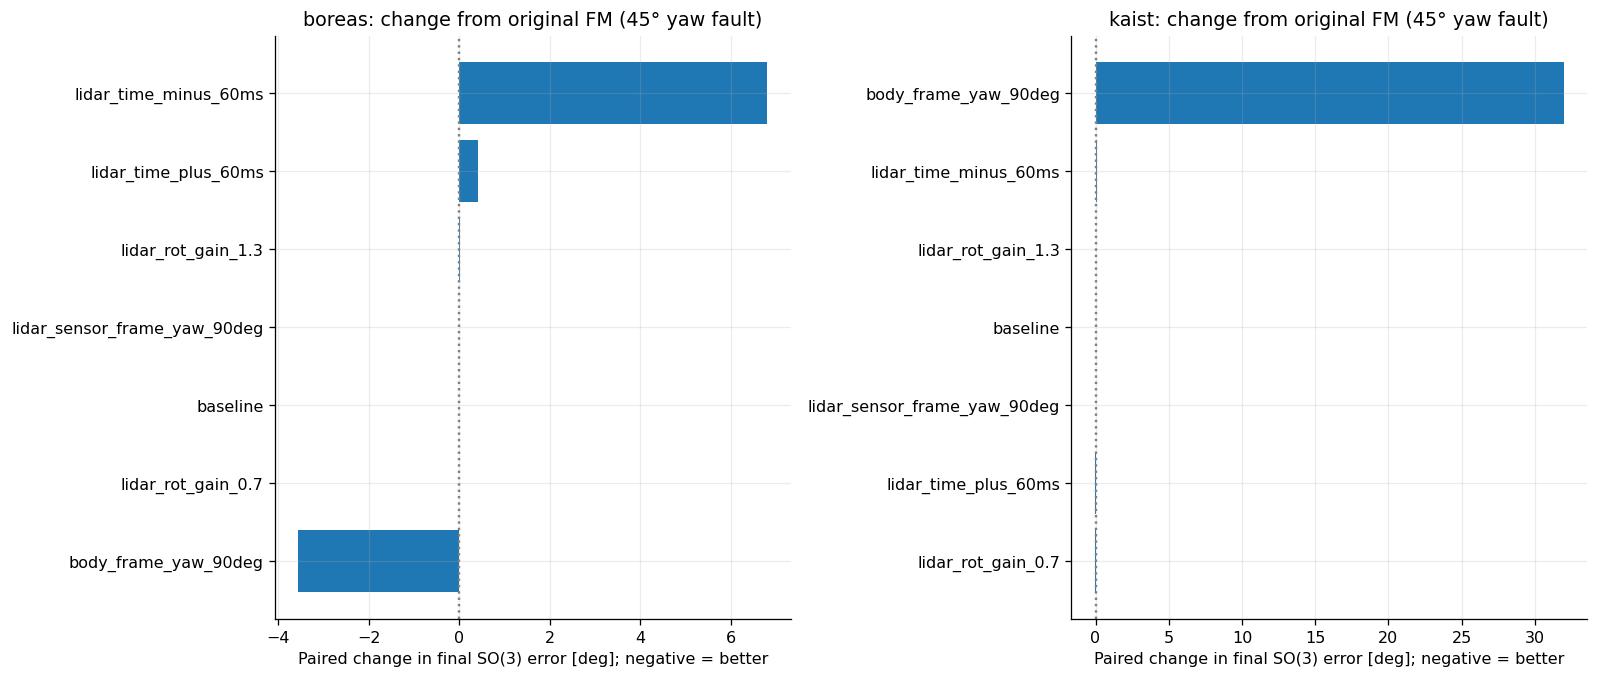

In [30]:
if grid_rows:
    summary=result
    domains=summary.domain.unique()
    fig,axs=plt.subplots(1,len(domains),figsize=(7*len(domains),6),squeeze=False)
    for ax,domain in zip(axs.flat,domains):
        part=summary[(summary.domain==domain)&(summary.initial_angle_deg==45.0)]
        if part.empty:continue
        bars=part.groupby("variant",as_index=False).median_change_deg.median().sort_values("median_change_deg")
        ax.barh(bars.variant,bars.median_change_deg)
        ax.axvline(0,c="gray",ls=":")
        ax.set(title=f"{domain}: change from original FM (45° yaw fault)",
               xlabel="Paired change in final SO(3) error [deg]; negative = better")
    finish_plot(fig,"07_paired_hypotheses.png")

## 13. Record the experiment and decide the next test

In [31]:
manifest = {
    "run": RUN_NAME,
    "kaist_sequence": KAIST_SEQUENCE,
    "kaist_raw_root": str(KAIST_ROOT),
    "kaist_lidar_pose_root": str(KAIST_LIDAR_ROOT),
    "kaist_right_lidar_pose_filename": KAIST_LIDAR_RIGHT_POSE_FILENAME,
    "kaist_sequence_split_in_notebook55": (
        "train" if KAIST_SEQUENCE in KAIST_TRAIN_SEQUENCES else
        "validation" if KAIST_SEQUENCE in KAIST_VAL_SEQUENCES else
        "test" if KAIST_SEQUENCE in KAIST_TEST_SEQUENCES else "other"),
    "kaist_nominal_source": KAIST_REFERENCE_SOURCE,
    "kaist_reference_configured": KAIST_REFERENCE_READY,
    "kaist_calibration_keys": list(KAIST_EXPECTED_KEYS),
    "kaist_nominal_T_B_sensor": {"imu": KAIST_T_B_I.tolist(), "lidar": KAIST_T_B_L.tolist(),
                                  "lidar_right": KAIST_T_B_L_RIGHT.tolist()},
    "kaist_taus_s": {"imu": KAIST_TAU_IMU_S, "lidar": KAIST_TAU_LIDAR_S,
                      "lidar_right": KAIST_TAU_LIDAR_RIGHT_S},
    "kaist_chronological_window_contiguity_verified": bool(KAIST_ASSUME_CONSECUTIVE_VALID_WINDOWS),
    "boreas_sequence": BOREAS_SEQUENCE,
    "boreas_topology": BOREAS_TOPOLOGY,
    "datasets_loaded": list(DOMAIN_WINDOWS),
    "boreas_nominal_source": "calib/T_*.txt",
    "boreas_uses_independent_scan_odometry": BOREAS_LIDAR_SCAN_ODOM,
    "fm_checkpoint": str(checkpoint_path), "fm_integration_steps": FM_STEPS, "fm_method": FM_METHOD,
    "window_duration_s": WINDOW_DURATION_S, "window_stride_s": WINDOW_STRIDE_S,
    "windows_per_domain": {k: len(v) for k, v in DOMAIN_WINDOWS.items()},
    "selected_augmented_domain": AUGMENT_DOMAIN, "selected_augmentation": dataclasses.asdict(AUGMENT),
    "selected_augmented_keys": list(AUGMENT_ONLY_KEYS),
    "sweep_variants": {k: dataclasses.asdict(ABLATIONS[k]) for k in GRID_VARIANTS},
    "seed": RANDOM_SEED,
    "notes": ["KAIST physical 3-sensor rig extracted from notebook 55 (FM .12); verify compatibility with FM .11",
              "KAIST nominal physical rig is not its training-time true_calibration augmentation",
              "Boreas extrinsics are nominal reference, not independently verified truth",
              "No true Boreas clock-offset labels used", "Physical data never rewritten",
              "Ablations intentionally include nonphysical stress tests",
              "KAIST window index scale is not independently verified physical chronology"],
}
if SAVE_PLOTS:
    (OUT / "04_experiment_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Results:", OUT if SAVE_PLOTS else "Saving disabled")
print("Recommended next question: does the intervention affect nominal (0°) drift,"
      " 45° recovery, and physical gyro/LiDAR agreement in the same direction?")

Results: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/kaist_boreas_fm_domain_shift_lab
Recommended next question: does the intervention affect nominal (0°) drift, 45° recovery, and physical gyro/LiDAR agreement in the same direction?


## How to interpret the experiments

1. **Check conventions first.** If inverting the LiDAR increments improves gyro–LiDAR agreement, inspect the actual odometry direction. If a nonzero timestamp shift helps, check scan-midpoint versus scan-start semantics. These checks are not GT labels for temporal calibration.
2. **Compare excitation and scale.** Compare IMU norms, LiDAR per-edge translation and rotation, and the model's 8-token inputs. Artificially scaling an odometry increment is a stress test, not necessarily a physically valid correction.
3. **Test coordinate robustness.** The consistent `lidar_sensor_frame_yaw_90deg` and `body_frame_yaw_90deg` experiments should preserve sensor motion relationships. If frozen FM behavior changes, a frame representation sensitivity is plausible.
4. **Keep topology fixed before interpreting domain gaps.** Default KAIST is 1 IMU + 2 LiDARs (`imu`, `lidar`, `lidar_right`), and default Boreas is DMU + Velodyne + Aeva LiDAR, to match the **three physical heads** seen in notebook 55. The LiDAR hardware and odometry estimators still differ. Switch `BOREAS_TOPOLOGY` to isolate Velodyne or Aeva effects.
5. **Don't conflate training experiments.** The attached notebook 55 trains FM .12, whereas notebook 04 loads FM .11. The nominal KAIST rig came from notebook 55, but checkpoint provenance for FM .11 must be confirmed separately if strict comparability matters.
6. **Train only after isolating the gap.** If a specific KAIST-side stressor reproduces Boreas-like errors, augment that source factor during training and evaluate both on held-out KAIST and untouched Boreas sequences.

**KAIST chronology caveat:** `kaist_window_starts` currently stores index × stride, *not authoritative timestamp metadata*. `KAIST_ASSUME_CONSECUTIVE_VALID_WINDOWS=False` remains the safe default. KAIST one-step and token experiments run with the full physical three-sensor rig; KAIST chronological rollouts are skipped until genuine continuity is verified. Boreas rollouts use measured scan timestamps.

**Boreas provenance:** Applanix-derived poses are never used as FM input; independent ICP odometry CSVs are used. Rotation-only corrections are compared with nominal reference matrices, not independently verified calibration truth.

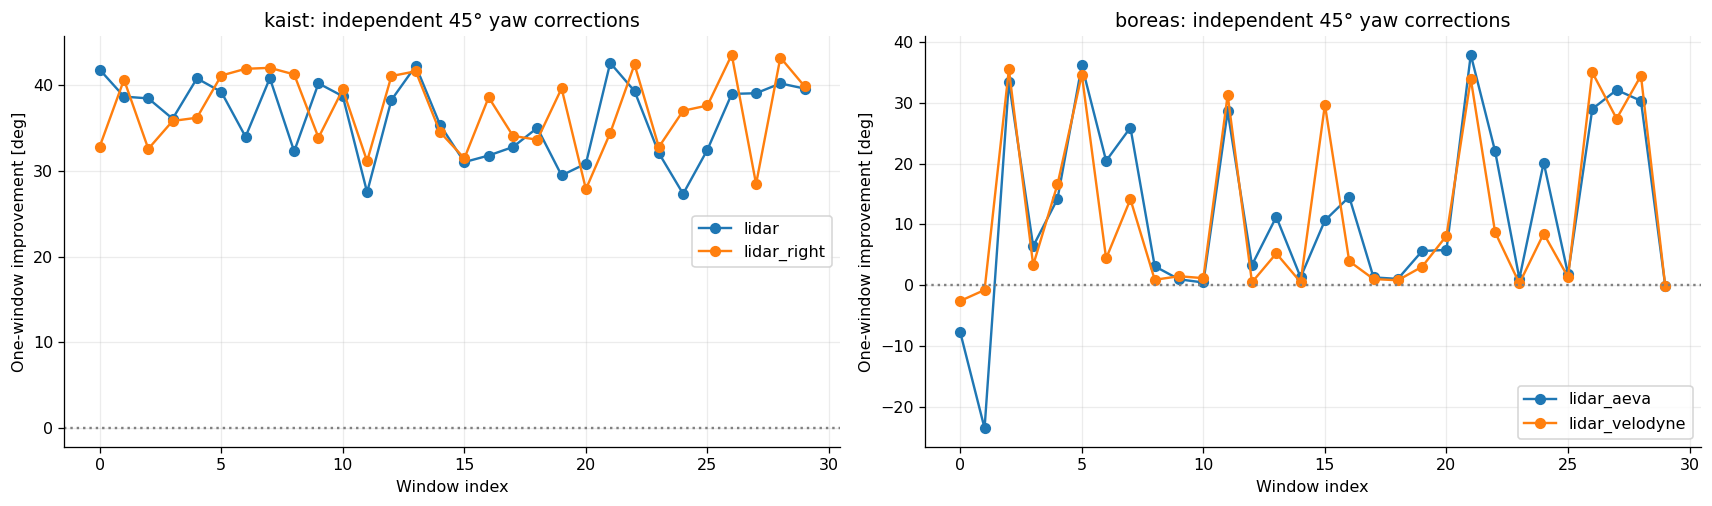

In [32]:
probe_rows = []

for domain in DOMAIN_WINDOWS:
    for i in range(len(DOMAIN_WINDOWS[domain])):
        for key in DOMAIN_FAULT_KEYS[domain]:
            for angle in (0.0, 45.0, 90.0):
                probe_rows.append(
                    score_one_window(
                        domain, fm, key, angle, 2, i, BASELINE
                    )
                )

probes = pd.DataFrame(probe_rows)

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))

for ax, domain in zip(axs, ("kaist", "boreas")):
    sub = probes[
        (probes.domain == domain)
        & (probes.initial_angle_deg == 45.0)
    ]

    for key, group in sub.groupby("sensor"):
        ax.plot(
            group.window,
            group.improvement_deg,
            "-o",
            label=key,
        )

    ax.axhline(0, color="gray", linestyle=":")
    ax.set(
        title=f"{domain}: independent 45° yaw corrections",
        xlabel="Window index",
        ylabel="One-window improvement [deg]",
    )
    ax.legend()

plt.tight_layout()
plt.show()

In [33]:
# A1 · Controls. The default measures many angles about yaw on ALL loaded windows.
# Set APP_AXES=("x", "y", "z", "xyz") for the full directional test (more FM calls).
APP_DOMAINS = tuple(domain for domain in ("kaist", "boreas") if domain in DOMAIN_WINDOWS)
APP_MODEL_LABEL = "FM .11"
APP_CONFIG = BASELINE  # deliberately not AUGMENT; don't accidentally reuse a previous stress-test setting
APP_AXES = ("z",)  # expand to ("x", "y", "z", "xyz") after first pass
APP_FOCUS_AXIS = "z"  # direction used in focused step plots / motion correlations
APP_ANGLES_DEG = (0., 5., 10., 15., 20., 30., 45., 60., 75., 90., 110., 130., 150., 170., 179.)
APP_WINDOW_INDICES = None  # None = every currently loaded window; otherwise e.g. (0, 3, 7, 10, 15, 20, 29)
APP_FOCUS_ANGLES_DEG = (15., 45., 90., 130., 170.)
APP_SENSORS = {}  # optional: {"boreas": ("lidar_velodyne",), "kaist": ("lidar",)}
APP_RUN_ALL_WINDOWS = True
APP_SAVE = SAVE_PLOTS
APP_PLOT = SHOW_PLOTS
APP_OUT = OUT / "appendix_all_windows"
if APP_SAVE: APP_OUT.mkdir(parents=True, exist_ok=True)

APP_DIRECTIONS = {"x": np.array([1., 0., 0.]), "y": np.array([0., 1., 0.]),
                  "z": np.array([0., 0., 1.]), "xyz": np.array([1., 1., 1.]) / np.sqrt(3.)}
APP_SELECTED_WINDOWS = {}
for domain in APP_DOMAINS:
    n = len(DOMAIN_WINDOWS[domain])
    inds = list(range(n)) if APP_WINDOW_INDICES is None else sorted(set(int(i) for i in APP_WINDOW_INDICES))
    if not inds or min(inds) < 0 or max(inds) >= n:
        raise ValueError(f"APP_WINDOW_INDICES outside loaded {domain} range 0..{n - 1}")
    APP_SELECTED_WINDOWS[domain] = inds
    if domain in APP_SENSORS and not set(APP_SENSORS[domain]).issubset(DOMAIN_FAULT_KEYS[domain]):
        raise ValueError(f"APP_SENSORS[{domain}] contains a key not in {DOMAIN_FAULT_KEYS[domain]}")
if not APP_AXES or not set(APP_AXES).issubset(APP_DIRECTIONS):
    raise ValueError(f"Unknown APP_AXES: {set(APP_AXES) - set(APP_DIRECTIONS)}")
if not np.all((np.asarray(APP_ANGLES_DEG) >= 0.) & (np.asarray(APP_ANGLES_DEG) < 180.)):
    raise ValueError("Injected angles must lie in [0, 180) degrees")
if APP_MODEL_LABEL not in MODELS:
    raise KeyError(f"Checkpoint {APP_MODEL_LABEL!r} is unavailable; available={tuple(MODELS)}")
if APP_FOCUS_AXIS not in APP_AXES:
    raise ValueError("APP_FOCUS_AXIS must be in APP_AXES; set it to the axis you want to diagnose")
APP_MODEL = MODELS[APP_MODEL_LABEL]
APP_JOBS = sum(len(APP_SELECTED_WINDOWS[d]) * len(APP_SENSORS.get(d, DOMAIN_FAULT_KEYS[d])) *
               (int(0. in APP_ANGLES_DEG) + (len(APP_ANGLES_DEG) - int(0. in APP_ANGLES_DEG)) * len(APP_AXES))
               for d in APP_DOMAINS)
print("Domains / windows:", {d: len(APP_SELECTED_WINDOWS[d]) for d in APP_DOMAINS})
print("Model:", APP_MODEL_LABEL, "| planned FM calls:", APP_JOBS)
print("Angles:", APP_ANGLES_DEG, "| axes:", APP_AXES)


Domains / windows: {'kaist': 30, 'boreas': 30}
Model: FM .11 | planned FM calls: 1800
Angles: (0.0, 5.0, 10.0, 15.0, 20.0, 30.0, 45.0, 60.0, 75.0, 90.0, 110.0, 130.0, 150.0, 170.0, 179.0) | axes: ('z',)


In [34]:
# A2 · Exact left-correction direction, independent one-step evaluation, and saved raw case table.
# For a left-applied update Exp(delta) @ R_est, the ideal update is log(R_ref @ R_est.T).
def app_left_ideal_rotvec(reference_T, estimate_T):
    R_ref = reference_T[0, :3, :3].detach().cpu().numpy().astype(float)
    R_est = estimate_T[0, :3, :3].detach().cpu().numpy().astype(float)
    return Rot.from_matrix(R_ref @ R_est.T).as_rotvec()

def app_correction_metrics(reference, initial, updated, prediction, key):
    ref_T = reference[key].transform
    before_T = initial[key].transform
    after_T = updated[key].transform
    R_before = before_T[0, :3, :3].detach().cpu().numpy().astype(float)
    R_after = after_T[0, :3, :3].detach().cpu().numpy().astype(float)
    ideal = app_left_ideal_rotvec(ref_T, before_T)
    applied = Rot.from_matrix(R_after @ R_before.T).as_rotvec()
    raw = prediction.predictions[key].delta_xi[0, :3].detach().cpu().numpy().astype(float)
    norm_i, norm_a = float(np.linalg.norm(ideal)), float(np.linalg.norm(applied))
    cosine = float(np.dot(ideal, applied) / (norm_i * norm_a)) if norm_i > 1e-7 and norm_a > 1e-9 else np.nan
    before = float(so3_err(before_T, ref_T).item())
    after = float(so3_err(after_T, ref_T).item())
    return {"initial_error_deg": before, "final_error_deg": after, "improvement_deg": before - after,
            "raw_prediction_deg": float(np.rad2deg(np.linalg.norm(raw))),
            "applied_step_deg": float(np.rad2deg(norm_a)),
            "ideal_step_deg": float(np.rad2deg(norm_i)), "correction_cosine": cosine,
            "along_ideal_deg": float(np.rad2deg(np.dot(applied, ideal) / norm_i)) if norm_i > 1e-7 else np.nan}

@torch.inference_mode()
def app_one_window_cases(domain, index):
    window = augmented_domain_window(domain, index, APP_CONFIG)
    reference = window.current_calibration
    keys = APP_SENSORS.get(domain, DOMAIN_FAULT_KEYS[domain])
    cases = []
    for key in keys:
        for angle in APP_ANGLES_DEG:
            # At angle=0, only one direction is meaningful: avoid duplicating the same exact case.
            axes = (APP_AXES[0],) if angle == 0. else APP_AXES
            for axis in axes:
                initial = inject_fault(reference, key, angle, APP_DIRECTIONS[axis])
                prediction = model_predict(APP_MODEL, window, initial)
                updated = update_one(initial, prediction, key)
                row = app_correction_metrics(reference, initial, updated, prediction, key)
                row.update(domain=domain, window=int(index), sensor=key, model=APP_MODEL_LABEL,
                           angle_deg=float(angle), axis=axis,
                           window_index=int(index),  # KAIST indexes are not authenticated physical timestamps
                           config="baseline" if APP_CONFIG == BASELINE else "edited")
                cases.append(row)
    return cases

app_rows = []
if APP_RUN_ALL_WINDOWS:
    jobs = [(domain, index) for domain, indices in APP_SELECTED_WINDOWS.items() for index in indices]
    for domain, index in tqdm(jobs, desc="Fresh-start one-step corrections per physical window"):
        app_rows.extend(app_one_window_cases(domain, index))
app_cases = pd.DataFrame(app_rows)
if not app_cases.empty:
    assert len(app_cases) == APP_JOBS, (len(app_cases), APP_JOBS)
    assert np.isfinite(app_cases[["initial_error_deg", "final_error_deg", "improvement_deg",
                                   "raw_prediction_deg", "applied_step_deg"]].to_numpy(float)).all()
    print("Evaluated:", len(app_cases), "independent cases")
    if APP_SAVE: app_cases.to_csv(APP_OUT / "all_windows_one_step_cases.csv", index=False)
    display(app_cases.groupby(["domain", "sensor", "angle_deg"], as_index=False).agg(
        median_improvement_deg=("improvement_deg", "median"), p10_improvement_deg=("improvement_deg", lambda x: x.quantile(.1)),
        p90_improvement_deg=("improvement_deg", lambda x: x.quantile(.9)),
        improved_fraction=("improvement_deg", lambda x: (x > 0.).mean()),
        median_applied_step_deg=("applied_step_deg", "median"), n=("improvement_deg", "size")).round(3))


Fresh-start one-step corrections per physical window:   0%|          | 0/60 [00:00<?, ?it/s]

Evaluated: 1800 independent cases


,domain,sensor,angle_deg,median_improvement_deg,p10_improvement_deg,p90_improvement_deg,improved_fraction,median_applied_step_deg,n
0,boreas,lidar_aeva,0.0,-1.952,-4.513,-0.630,0.000,1.952,30
1,boreas,lidar_aeva,5.0,1.405,-0.277,3.456,0.800,2.102,30
2,boreas,lidar_aeva,10.0,2.888,0.142,8.260,0.933,3.740,30
3,boreas,lidar_aeva,15.0,5.872,0.283,11.980,0.933,6.294,30
4,boreas,lidar_aeva,20.0,9.147,0.722,15.978,0.933,10.984,30
5,boreas,lidar_aeva,30.0,14.442,1.042,24.326,0.933,18.852,30
6,boreas,lidar_aeva,45.0,8.541,0.413,32.211,0.900,11.465,30
7,boreas,lidar_aeva,60.0,20.207,0.901,47.881,0.900,20.597,30
8,boreas,lidar_aeva,75.0,34.231,1.260,65.927,0.900,34.755,30
9,boreas,lidar_aeva,90.0,67.763,2.978,78.836,0.900,69.398,30


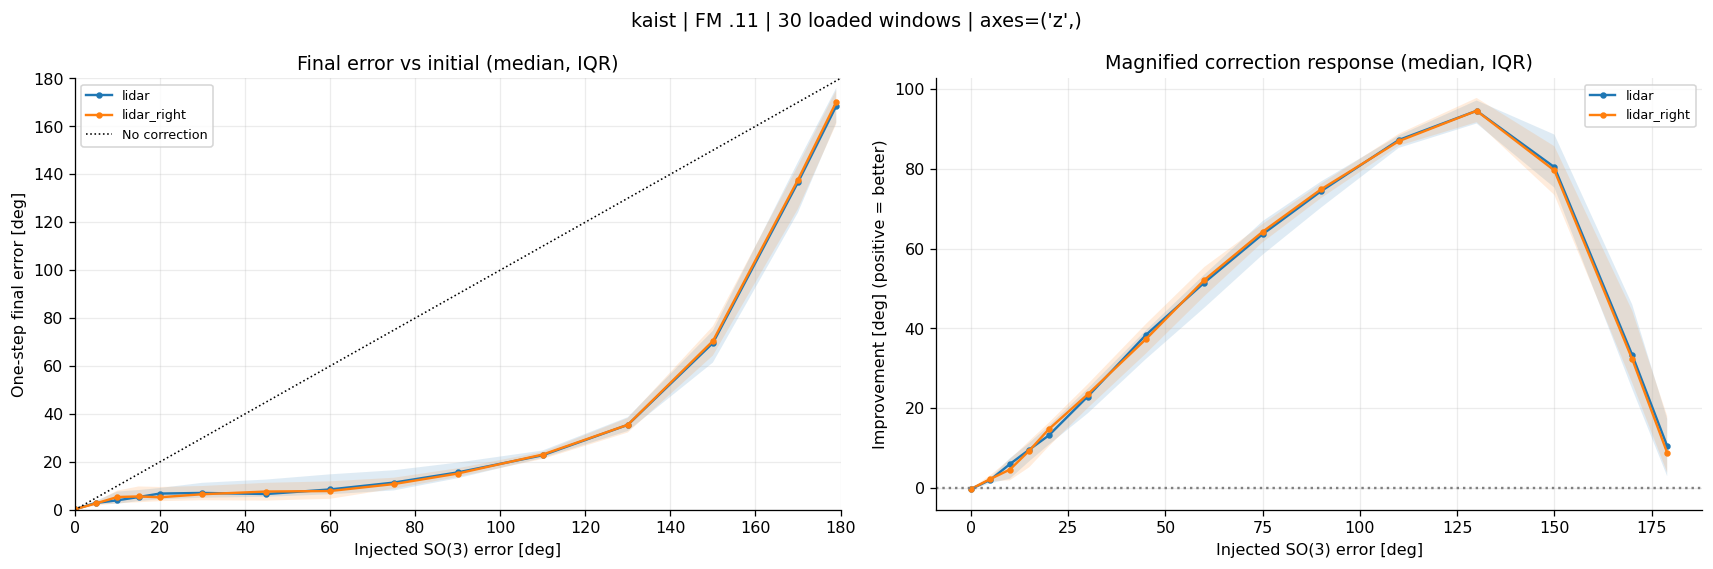

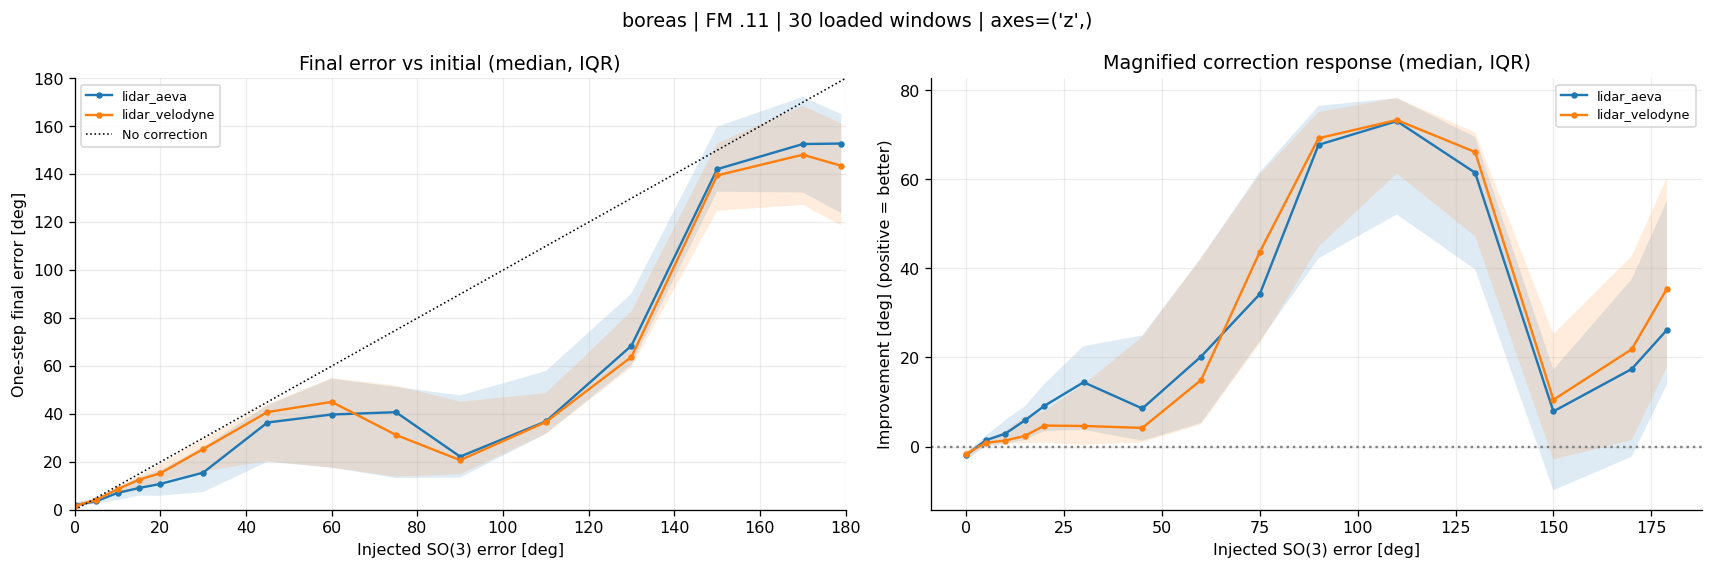

In [35]:
# A3 · Show BOTH the familiar final-vs-initial curve AND the less misleading improvement curve.
# Interquartile bands show window/axis variability. A diagonal alone hides 1–3 degree corrections.
if not app_cases.empty:
    for domain in APP_DOMAINS:
        sub = app_cases[app_cases.domain == domain]
        fig, axs = plt.subplots(1, 2, figsize=(15, 5.0))
        for sensor, group in sub.groupby("sensor"):
            agg = group.groupby("angle_deg").agg(
                median_final=("final_error_deg", "median"),
                final_q25=("final_error_deg", lambda x: x.quantile(.25)),
                final_q75=("final_error_deg", lambda x: x.quantile(.75)),
                median_improvement=("improvement_deg", "median"),
                improve_q25=("improvement_deg", lambda x: x.quantile(.25)),
                improve_q75=("improvement_deg", lambda x: x.quantile(.75))).sort_index()
            x = agg.index.to_numpy(float)
            axs[0].plot(x, agg.median_final.to_numpy(float), "-o", markersize=3, label=sensor)
            axs[0].fill_between(x, agg.final_q25.to_numpy(float), agg.final_q75.to_numpy(float), alpha=.14)
            axs[1].plot(x, agg.median_improvement.to_numpy(float), "-o", markersize=3, label=sensor)
            axs[1].fill_between(x, agg.improve_q25.to_numpy(float), agg.improve_q75.to_numpy(float), alpha=.14)
        axs[0].plot([0, 180], [0, 180], "k:", linewidth=1, label="No correction")
        axs[0].set(xlabel="Injected SO(3) error [deg]", ylabel="One-step final error [deg]",
                   title="Final error vs initial (median, IQR)", xlim=(0, 180), ylim=(0, 180))
        axs[1].axhline(0, linestyle=":", color="gray")
        axs[1].set(xlabel="Injected SO(3) error [deg]", ylabel="Improvement [deg] (positive = better)",
                   title="Magnified correction response (median, IQR)")
        axs[0].legend(fontsize=8); axs[1].legend(fontsize=8)
        fig.suptitle(f"{domain} | {APP_MODEL_LABEL} | {len(APP_SELECTED_WINDOWS[domain])} loaded windows | axes={APP_AXES}")
        fig.tight_layout()
        if APP_SAVE: fig.savefig(APP_OUT / f"response_by_angle_{domain}.png", dpi=155, bbox_inches="tight")
        if APP_PLOT: plt.show()
        plt.close(fig)


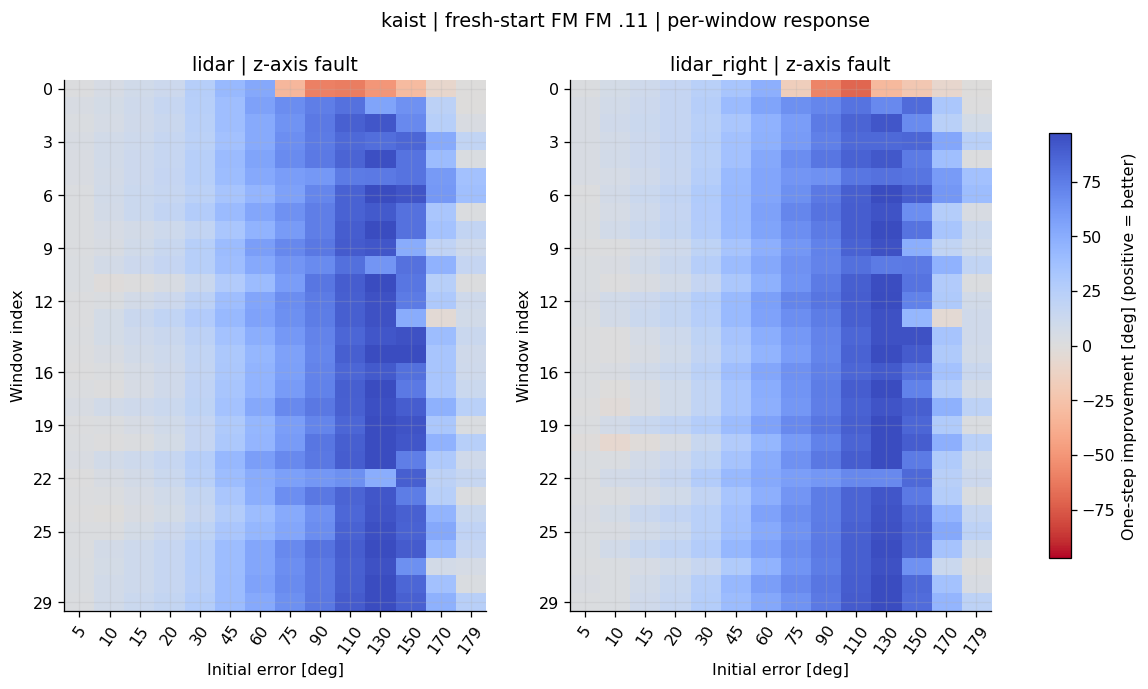

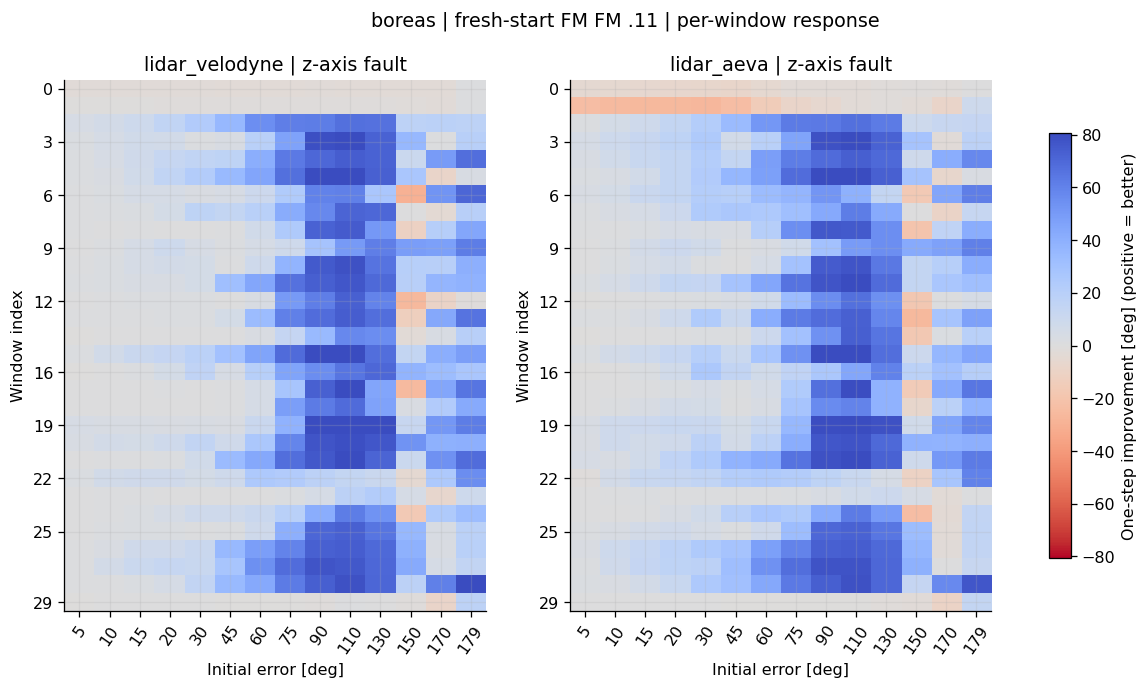

In [36]:
# A4 · Window-by-angle improvement heatmaps: do a few informative windows explain the rollout recovery?
# Create separate panels for requested axes to avoid hiding sensitivity to rotation direction.
if not app_cases.empty:
    for domain in APP_DOMAINS:
        sensors = APP_SENSORS.get(domain, DOMAIN_FAULT_KEYS[domain])
        for axis in APP_AXES:
            sub = app_cases[(app_cases.domain == domain) & (app_cases.axis == axis) & (app_cases.angle_deg > 0)]
            if sub.empty: continue
            fig, axes = plt.subplots(1, len(sensors), figsize=(6.5 * len(sensors), 6.0), squeeze=False)
            limits = np.nanpercentile(np.abs(sub.improvement_deg.to_numpy(float)), 98)
            limits = max(float(limits), 0.5)
            for ax, sensor in zip(axes.flat, sensors):
                group = sub[sub.sensor == sensor]
                pivot = group.pivot(index="window", columns="angle_deg", values="improvement_deg")
                pivot = pivot.reindex(index=APP_SELECTED_WINDOWS[domain], columns=[a for a in APP_ANGLES_DEG if a > 0])
                img = ax.imshow(pivot.to_numpy(float), aspect="auto", cmap="coolwarm_r", vmin=-limits, vmax=limits)
                ax.set(title=f"{sensor} | {axis}-axis fault", xlabel="Initial error [deg]", ylabel="Window index")
                ax.set_xticks(np.arange(len(pivot.columns)), labels=[f"{v:g}" for v in pivot.columns], rotation=55)
                y_pos = np.unique(np.linspace(0, len(pivot) - 1, min(10, len(pivot)), dtype=int))
                ax.set_yticks(y_pos, labels=pivot.index.to_numpy()[y_pos])
            fig.colorbar(img, ax=list(axes.flat), shrink=.8, label="One-step improvement [deg] (positive = better)")
            fig.suptitle(f"{domain} | fresh-start FM {APP_MODEL_LABEL} | per-window response")
            if APP_SAVE: fig.savefig(APP_OUT / f"heatmap_{domain}_{axis}.png", dpi=155, bbox_inches="tight")
            if APP_PLOT: plt.show()
            plt.close(fig)


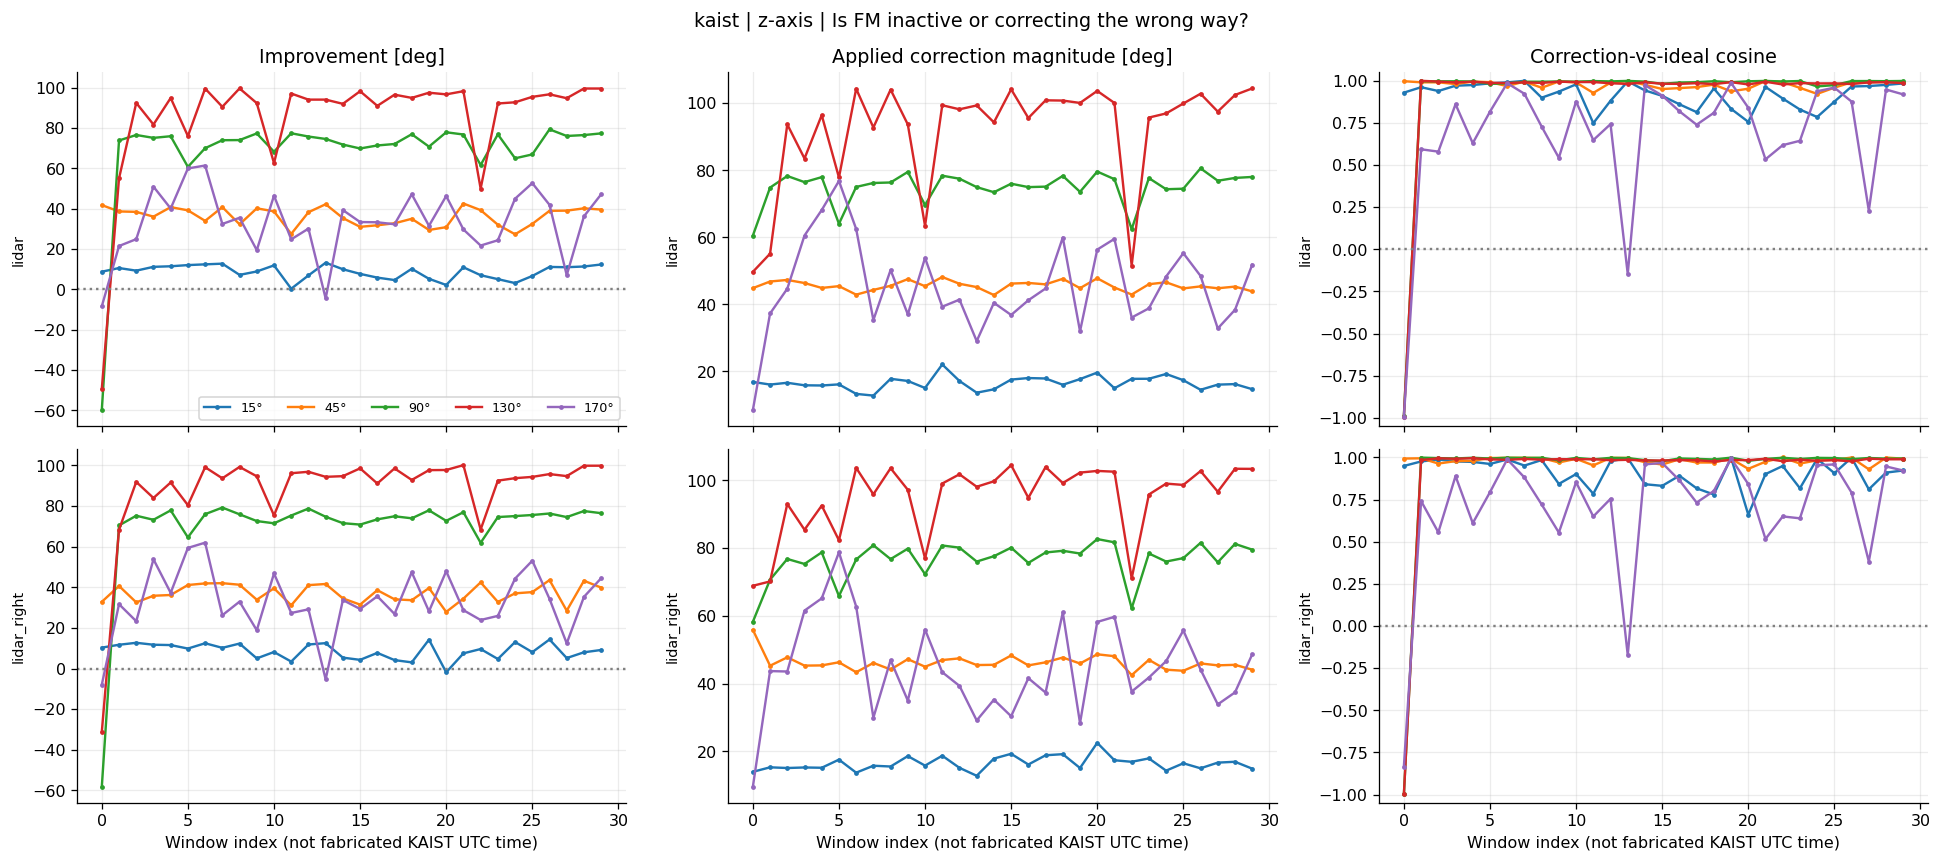

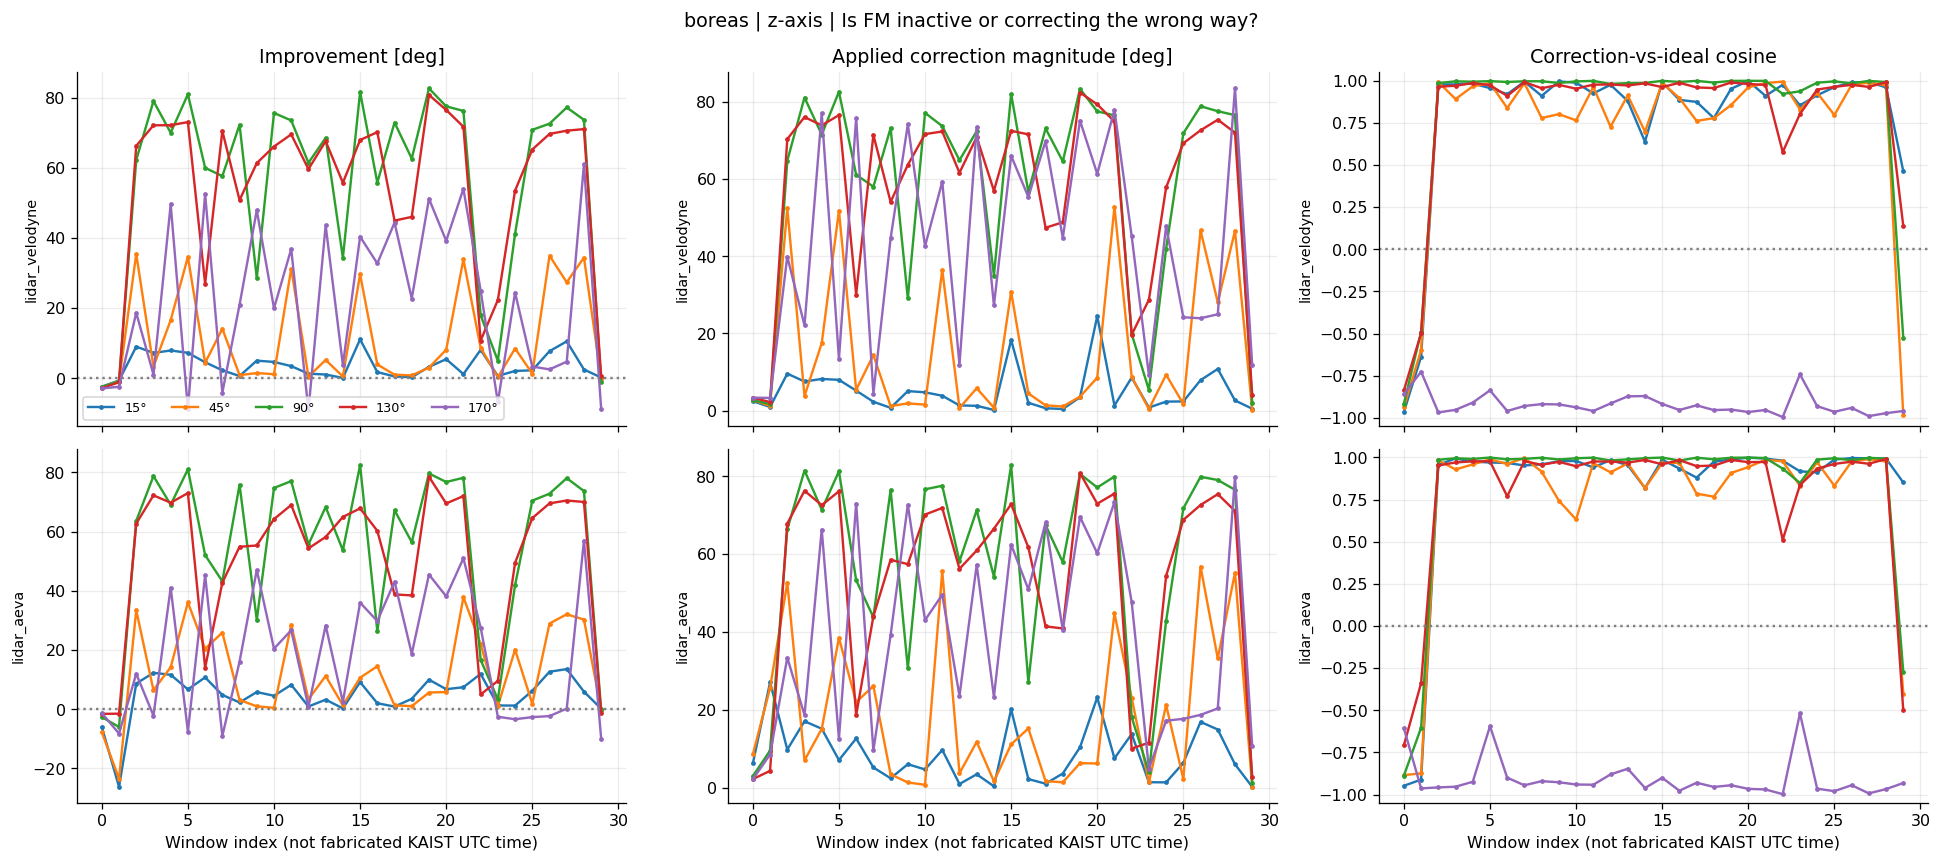

Aggregated correction strength and direction (omit angle 0 from direction cosine):


,domain,sensor,angle_deg,median_step_deg,median_cosine,median_along_ideal_deg,positive_direction_fraction,improved_fraction
0,boreas,lidar_aeva,5.0,2.102,0.944,1.593,0.833,0.800
1,boreas,lidar_aeva,10.0,3.740,0.973,2.919,0.933,0.933
2,boreas,lidar_aeva,15.0,6.294,0.973,5.929,0.933,0.933
3,boreas,lidar_aeva,20.0,10.984,0.977,10.048,0.933,0.933
4,boreas,lidar_aeva,30.0,18.852,0.963,17.043,0.933,0.933
5,boreas,lidar_aeva,45.0,11.465,0.951,8.639,0.900,0.900
6,boreas,lidar_aeva,60.0,20.597,0.979,20.329,0.900,0.900
7,boreas,lidar_aeva,75.0,34.755,0.988,34.450,0.900,0.900
8,boreas,lidar_aeva,90.0,69.398,0.992,68.962,0.900,0.900
9,boreas,lidar_aeva,110.0,74.732,0.988,74.157,0.900,0.900


In [37]:
# A5 · Analyze correction strength, direction, and harmful updates across all windows.
# A direction cosine close to +1 points toward the correct left-SO(3) correction,
# close to -1 points away. NaN at 0° or near-zero predicted updates is intentional.
if not app_cases.empty:
    focus_angles = [float(a) for a in APP_FOCUS_ANGLES_DEG if a in APP_ANGLES_DEG and a > 0]
    for domain in APP_DOMAINS:
        sensors = APP_SENSORS.get(domain, DOMAIN_FAULT_KEYS[domain])
        fig, axes = plt.subplots(len(sensors), 3, figsize=(17, 3.8 * len(sensors)), squeeze=False, sharex="col")
        for j, sensor in enumerate(sensors):
            group = app_cases[(app_cases.domain == domain) & (app_cases.sensor == sensor) & (app_cases.axis == APP_FOCUS_AXIS)]
            for angle in focus_angles:
                chunk = group[group.angle_deg == angle].groupby("window", as_index=False).agg(
                    improvement=("improvement_deg", "median"),
                    step=("applied_step_deg", "median"),
                    cosine=("correction_cosine", "median"))
                if chunk.empty: continue
                axes[j, 0].plot(chunk.window, chunk.improvement, "-o", ms=2, label=f"{angle:g}°")
                axes[j, 1].plot(chunk.window, chunk.step, "-o", ms=2, label=f"{angle:g}°")
                axes[j, 2].plot(chunk.window, chunk.cosine, "-o", ms=2, label=f"{angle:g}°")
            axes[j, 0].axhline(0, c="gray", ls=":")
            axes[j, 2].axhline(0, c="gray", ls=":")
            axes[j, 2].set_ylim(-1.05, 1.05)
            for ax in axes[j]: ax.set_ylabel(sensor, fontsize=9)
        for ax, title in zip(axes[0], ("Improvement [deg]", "Applied correction magnitude [deg]", "Correction-vs-ideal cosine")):
            ax.set_title(title)
        for ax in axes[-1]: ax.set_xlabel("Window index (not fabricated KAIST UTC time)")
        axes[0, 0].legend(fontsize=8, ncol=min(5, len(focus_angles)))
        fig.suptitle(f"{domain} | {APP_FOCUS_AXIS}-axis | Is FM inactive or correcting the wrong way?")
        fig.tight_layout()
        if APP_SAVE: fig.savefig(APP_OUT / f"magnitude_direction_{domain}.png", dpi=155, bbox_inches="tight")
        if APP_PLOT: plt.show()
        plt.close(fig)

    print("Aggregated correction strength and direction (omit angle 0 from direction cosine):")
    display(app_cases[(app_cases.angle_deg > 0) & (app_cases.axis == APP_FOCUS_AXIS)].groupby(["domain", "sensor", "angle_deg"], as_index=False).agg(
        median_step_deg=("applied_step_deg", "median"), median_cosine=("correction_cosine", "median"),
        median_along_ideal_deg=("along_ideal_deg", "median"),
        positive_direction_fraction=("correction_cosine", lambda x: (x.dropna() > 0.).mean() if x.notna().any() else np.nan),
        improved_fraction=("improvement_deg", lambda x: (x > 0.).mean())).round(3))


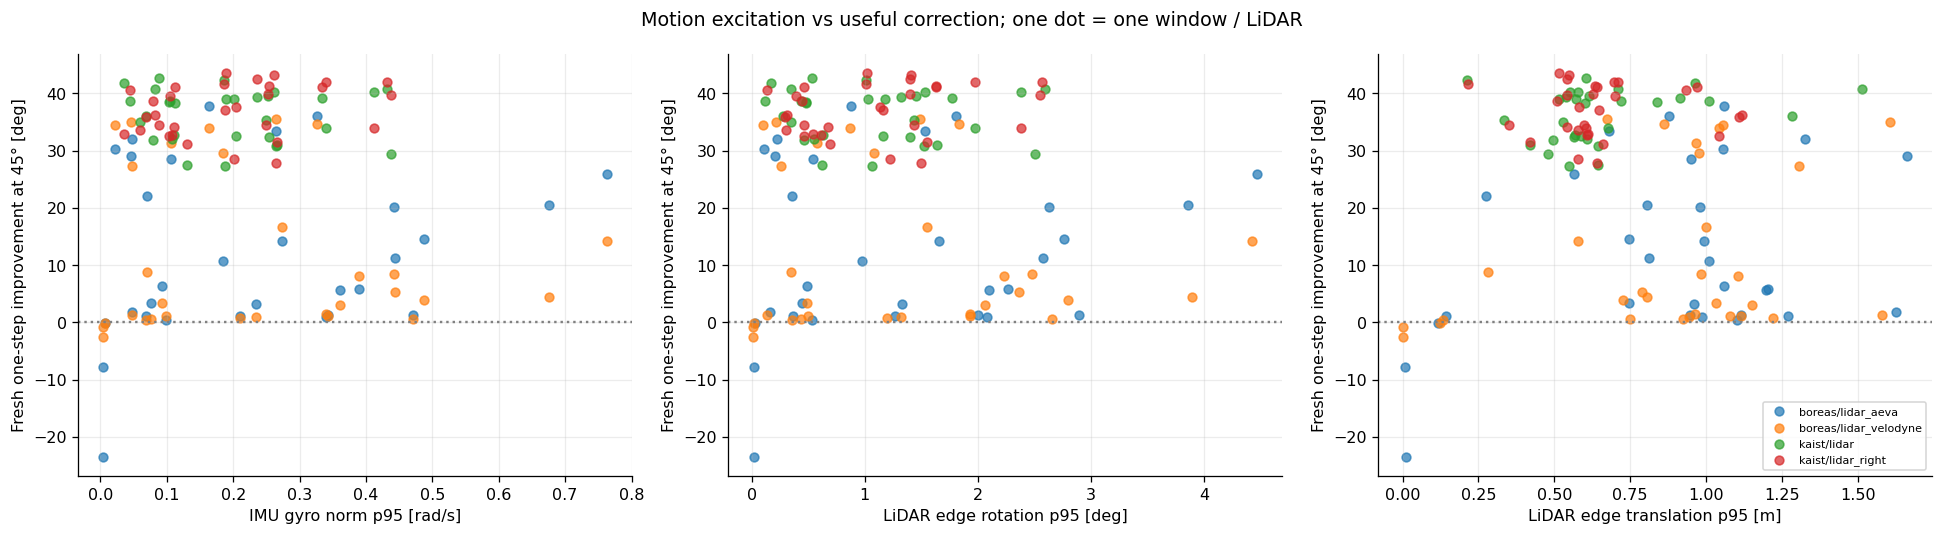

,domain,sensor,kind,window,improvement_deg,gyro_p95_radps,lidar_rot_p95_deg
0,boreas,lidar_aeva,worst,1,-23.463,0.004,0.022
1,boreas,lidar_aeva,best,21,37.854,0.164,0.873
2,boreas,lidar_velodyne,worst,0,-2.561,0.004,0.013
3,boreas,lidar_velodyne,best,2,35.445,0.264,1.491
4,kaist,lidar,worst,24,27.325,0.188,1.061
5,kaist,lidar,best,21,42.597,0.089,0.532
6,kaist,lidar_right,worst,20,27.873,0.264,1.498
7,kaist,lidar_right,best,26,43.544,0.189,1.015


In [38]:
# A6 · Does *measured* motion excitation explain which windows provide useful corrections?
# This is correlation, not proof of observability; the 30 windows are not independent trials.
app_motion_rows = []
if not app_cases.empty:
    for domain, indices in APP_SELECTED_WINDOWS.items():
        for index in indices:
            features = raw_feature_arrays(DOMAIN_WINDOWS[domain][index])
            imu_rates = [np.percentile(v, 95) for k, v in features.items() if k.endswith("/gyro/norm") and len(v)]
            for sensor in APP_SENSORS.get(domain, DOMAIN_FAULT_KEYS[domain]):
                rot = features.get(f"{sensor}/lidar/rotation_deg", np.asarray([]))
                trans = features.get(f"{sensor}/lidar/translation_m", np.asarray([]))
                app_motion_rows.append({"domain": domain, "window": index, "sensor": sensor,
                    "gyro_p95_radps": float(np.median(imu_rates)) if imu_rates else np.nan,
                    "lidar_rot_p95_deg": float(np.percentile(rot, 95)) if len(rot) else np.nan,
                    "lidar_trans_p95_m": float(np.percentile(trans, 95)) if len(trans) else np.nan})
app_motion = pd.DataFrame(app_motion_rows)
if not app_motion.empty:
    focus_angle = 45.0 if 45.0 in APP_ANGLES_DEG else float(APP_ANGLES_DEG[1])
    app_excitation = (app_cases[(app_cases.angle_deg == focus_angle) & (app_cases.axis == APP_FOCUS_AXIS)]
                      .groupby(["domain", "window", "sensor"], as_index=False)
                      .agg(improvement_deg=("improvement_deg", "median"), step_deg=("applied_step_deg", "median"))
                      .merge(app_motion, on=["domain", "window", "sensor"], validate="one_to_one"))
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))
    for (domain, sensor), group in app_excitation.groupby(["domain", "sensor"]):
        for ax, metric in zip(axes, ("gyro_p95_radps", "lidar_rot_p95_deg", "lidar_trans_p95_m")):
            ax.scatter(group[metric], group.improvement_deg, alpha=.7, s=30, label=f"{domain}/{sensor}")
    for ax, xlabel in zip(axes, ("IMU gyro norm p95 [rad/s]", "LiDAR edge rotation p95 [deg]", "LiDAR edge translation p95 [m]")):
        ax.axhline(0, c="gray", ls=":")
        ax.set(xlabel=xlabel, ylabel=f"Fresh one-step improvement at {focus_angle:g}° [deg]")
    axes[-1].legend(fontsize=7, loc="best")
    fig.suptitle("Motion excitation vs useful correction; one dot = one window / LiDAR")
    fig.tight_layout()
    if APP_SAVE:
        fig.savefig(APP_OUT / "motion_excitation_vs_improvement.png", dpi=155, bbox_inches="tight")
        app_excitation.to_csv(APP_OUT / "motion_excitation_by_window.csv", index=False)
    if APP_PLOT: plt.show()
    plt.close(fig)

    # Find windows that help or hurt despite using an identical initial fault.
    best_worst = []
    for (domain, sensor), part in app_excitation.groupby(["domain", "sensor"]):
        s = part.sort_values("improvement_deg")
        for kind, item in (("worst", s.iloc[0]), ("best", s.iloc[-1])):
            best_worst.append({"domain":domain, "sensor":sensor, "kind":kind, "window":int(item.window),
                               "improvement_deg":float(item.improvement_deg), "gyro_p95_radps":float(item.gyro_p95_radps),
                               "lidar_rot_p95_deg":float(item.lidar_rot_p95_deg)})
    display(pd.DataFrame(best_worst).round(3))

In [39]:
# A7 · Select a controlled stateful experiment (independent of A1–A6 results).
APP_REPLAY_DOMAIN = "boreas"
APP_REPLAY_KEYS = tuple(DOMAIN_FAULT_KEYS.get(APP_REPLAY_DOMAIN, ()))
APP_REPLAY_ANGLES_DEG = (0., 45., 90., 130., 170.)
APP_REPLAY_AXIS = "z"
APP_REPLAY_START = 0
APP_REPLAY_STEPS = 15
APP_REPLAY_USE_BEST_WINDOW = False  # optional diagnostic selection using prior sweep results; never a fair model score

@torch.inference_mode()
def app_replay_case(domain, sensor, angle_deg, axis, *, start, count, mode, fixed_index=None):
    if domain == "kaist" and not KAIST_ASSUME_CONSECUTIVE_VALID_WINDOWS:
        raise ValueError("KAIST chronology is not verified. Only use fresh one-step tests until physical starts are known.")
    indices = list(range(start, min(len(DOMAIN_WINDOWS[domain]), start + count)))
    if len(indices) < 2:
        raise ValueError("Need at least two consecutive loaded windows")
    physical_starts = np.asarray(DOMAIN_TIMES[domain])[indices]
    if np.any(np.abs(np.diff(physical_starts) - WINDOW_STRIDE_S) > 1e-3):
        raise ValueError("Selected windows have a physical gap; cannot treat as chronological")
    first = augmented_domain_window(domain, indices[0], BASELINE)
    truth = first.current_calibration
    states = inject_fault(truth, sensor, angle_deg, APP_DIRECTIONS[axis])
    out = []
    for step, index in enumerate(indices):
        j = index if mode == "chronological" else (start if fixed_index is None else fixed_index)
        window = first if j == start else augmented_domain_window(domain, j, BASELINE)
        for key in truth:
            torch.testing.assert_close(window.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
        pred = model_predict(APP_MODEL, window, states)
        updated = update_one(states, pred, sensor)
        metrics = app_correction_metrics(truth, states, updated, pred, sensor)
        out.append({"domain": domain, "sensor": sensor, "angle_deg": float(angle_deg), "axis": axis,
                    "mode": mode, "update_step": step + 1, "source_window": j,
                    "elapsed_physical_s": float(physical_starts[step] - physical_starts[0] + WINDOW_DURATION_S)
                        if mode == "chronological" else np.nan, **metrics})
        states = updated
    return out

app_replay_rows = []
if APP_REPLAY_DOMAIN in DOMAIN_WINDOWS:
    for sensor in APP_REPLAY_KEYS:
        for angle in tqdm(APP_REPLAY_ANGLES_DEG, desc=f"New-window vs replay | {sensor}"):
            for mode in ("chronological", "repeat_first"):
                app_replay_rows.extend(app_replay_case(APP_REPLAY_DOMAIN, sensor, angle, APP_REPLAY_AXIS,
                     start=APP_REPLAY_START, count=APP_REPLAY_STEPS, mode=mode))
            if APP_REPLAY_USE_BEST_WINDOW:
                if app_cases.empty:
                    raise ValueError("Run A2 before selecting the best window from its one-step results")
                candidates = app_cases[(app_cases.domain == APP_REPLAY_DOMAIN) & (app_cases.sensor == sensor) &
                                       (app_cases.angle_deg == angle) & (app_cases.axis == APP_REPLAY_AXIS)]
                if candidates.empty:
                    raise ValueError("No fresh one-step cases for requested replay angle / axis")
                best_index = int(candidates.sort_values("improvement_deg").iloc[-1].window)
                app_replay_rows.extend(app_replay_case(APP_REPLAY_DOMAIN, sensor, angle, APP_REPLAY_AXIS,
                     start=APP_REPLAY_START, count=APP_REPLAY_STEPS, mode="repeat_oracle_best", fixed_index=best_index))
app_replay = pd.DataFrame(app_replay_rows)
if not app_replay.empty:
    summary = app_replay.sort_values("update_step").groupby(["domain", "sensor", "angle_deg", "mode"]).tail(1)
    display(summary[["domain", "sensor", "angle_deg", "mode", "initial_error_deg", "final_error_deg"]].round(3))
    if APP_SAVE: app_replay.to_csv(APP_OUT / "repeat_fixed_window_vs_chronological.csv", index=False)


New-window vs replay | lidar_velodyne:   0%|          | 0/5 [00:00<?, ?it/s]

New-window vs replay | lidar_aeva:   0%|          | 0/5 [00:00<?, ?it/s]

,domain,sensor,angle_deg,mode,initial_error_deg,final_error_deg
224,boreas,lidar_aeva,90.0,chronological,27.437,27.897
149,boreas,lidar_velodyne,170.0,repeat_first,152.346,149.643
209,boreas,lidar_aeva,45.0,repeat_first,89.747,91.276
134,boreas,lidar_velodyne,170.0,chronological,24.489,24.631
164,boreas,lidar_aeva,0.0,chronological,4.865,4.366
179,boreas,lidar_aeva,0.0,repeat_first,69.875,72.331
119,boreas,lidar_velodyne,130.0,repeat_first,168.510,171.184
104,boreas,lidar_velodyne,130.0,chronological,30.286,30.272
74,boreas,lidar_velodyne,90.0,chronological,13.926,14.250
59,boreas,lidar_velodyne,45.0,repeat_first,82.332,85.034


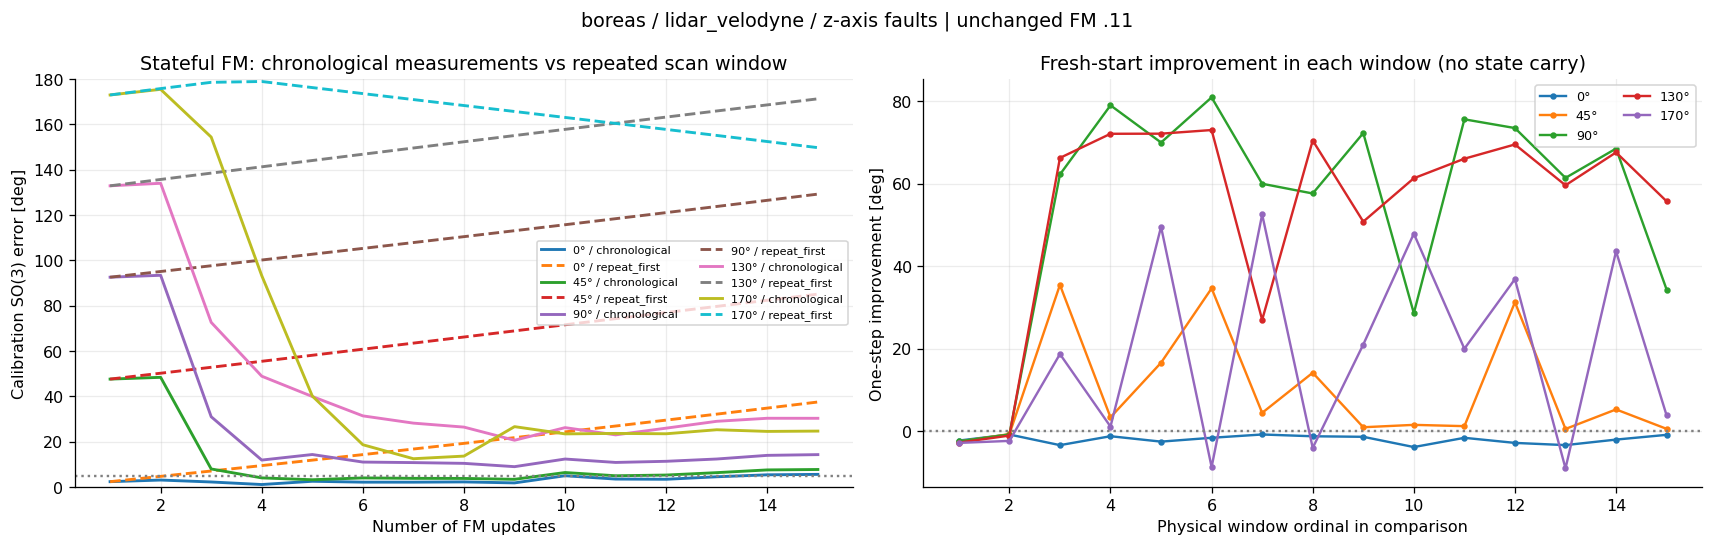

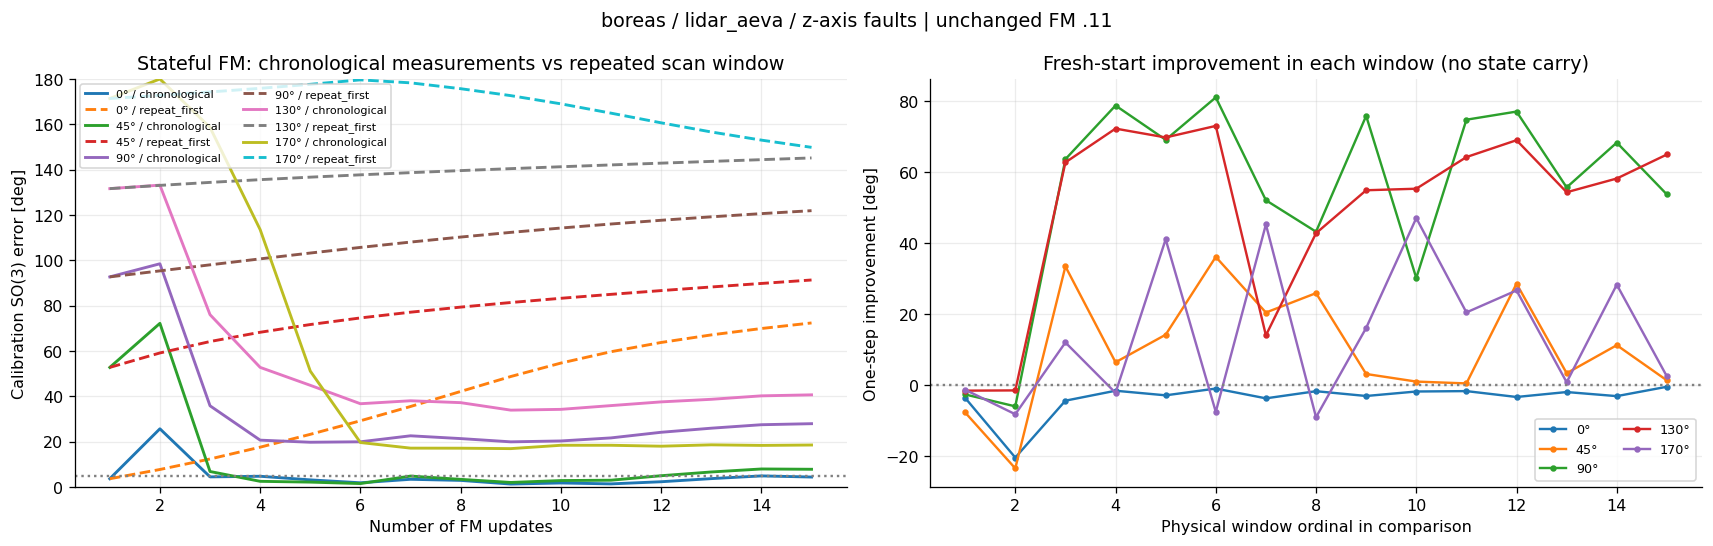

In [40]:
# A8 · Visual comparison: does fresh *information* help beyond multiple iterations?
# Fresh single-window points use the original error every time (not a carried calibration).
if not app_replay.empty:
    domain = APP_REPLAY_DOMAIN
    for sensor in APP_REPLAY_KEYS:
        sub = app_replay[app_replay.sensor == sensor]
        fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
        for angle in APP_REPLAY_ANGLES_DEG:
            for mode, linestyle in (("chronological", "-"), ("repeat_first", "--"), ("repeat_oracle_best", ":")):
                chunk = sub[(sub.angle_deg == angle) & (sub["mode"] == mode)].sort_values("update_step")
                if chunk.empty: continue
                axes[0].plot(chunk.update_step, chunk.final_error_deg, linestyle, linewidth=1.8,
                             label=f"{angle:g}° / {mode}")
            fresh = app_cases[(app_cases.domain == domain) & (app_cases.sensor == sensor) &
                              (app_cases.angle_deg == angle) & (app_cases.axis == APP_REPLAY_AXIS)] if not app_cases.empty else pd.DataFrame()
            if not fresh.empty:
                fresh = fresh[(fresh.window >= APP_REPLAY_START) & (fresh.window < APP_REPLAY_START + APP_REPLAY_STEPS)].sort_values("window")
                axes[1].plot(fresh.window - APP_REPLAY_START + 1, fresh.improvement_deg, "-o", ms=3, label=f"{angle:g}°")
        axes[0].axhline(5, c="gray", ls=":")
        axes[0].set(title="Stateful FM: chronological measurements vs repeated scan window",
                    xlabel="Number of FM updates", ylabel="Calibration SO(3) error [deg]", ylim=(0, 180))
        axes[1].axhline(0, c="gray", ls=":")
        axes[1].set(title="Fresh-start improvement in each window (no state carry)",
                    xlabel="Physical window ordinal in comparison", ylabel="One-step improvement [deg]")
        axes[0].legend(fontsize=7, ncol=2)
        axes[1].legend(fontsize=8, ncol=2)
        fig.suptitle(f"{domain} / {sensor} / {APP_REPLAY_AXIS}-axis faults | unchanged FM .11")
        fig.tight_layout()
        if APP_SAVE: fig.savefig(APP_OUT / f"chronological_vs_repeat_{sensor}.png", dpi=155, bbox_inches="tight")
        if APP_PLOT: plt.show()
        plt.close(fig)


In [41]:
# A9 · Reproducibility. Save controls after experiments, without replacing the main notebook manifest.
if APP_SAVE:
    details = {
        "model": APP_MODEL_LABEL, "checkpoint": str(FM_CHECKPOINT), "domain_sequence_ids": {"kaist": KAIST_SEQUENCE, "boreas": BOREAS_SEQUENCE},
        "boreas_topology": BOREAS_TOPOLOGY, "window_duration_s": WINDOW_DURATION_S, "window_stride_s": WINDOW_STRIDE_S,
        "window_indices": APP_SELECTED_WINDOWS, "angles_deg": APP_ANGLES_DEG, "axes": APP_AXES, "focus_axis":APP_FOCUS_AXIS,
        "model_config": dataclasses.asdict(APP_CONFIG), "affected_keys": APP_SENSORS,
        "fm_steps": FM_STEPS, "fm_method": FM_METHOD, "rotation_gain": ROLL_ROTATION_GAIN,
        "max_rotation_step_deg": MAX_ROTATION_STEP_DEG,
        "one_step_cases": len(app_cases), "replay_cases": len(app_replay),
        "replay": {"domain":APP_REPLAY_DOMAIN,"keys":APP_REPLAY_KEYS,"angles_deg":APP_REPLAY_ANGLES_DEG,
                   "axis":APP_REPLAY_AXIS,"start":APP_REPLAY_START,"steps":APP_REPLAY_STEPS,
                   "oracle_best_enabled":APP_REPLAY_USE_BEST_WINDOW},
        "limitations": ["KAIST window ordinal is not verified physical time", "Only currently loaded windows are analyzed",
                        "Boreas extrinsics are nominal not independently verified truth", "Reference calibrations used solely to inject and score faults"]}
    (APP_OUT / "diagnostic_manifest.json").write_text(json.dumps(details, indent=2, default=str), encoding="utf8")
    print("Appendix files:", APP_OUT)
print("Next: check improvement heatmaps, correction-vector cosine, and chronological-vs-repeat before designing augmentation.")


Appendix files: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/kaist_boreas_fm_domain_shift_lab/appendix_all_windows
Next: check improvement heatmaps, correction-vector cosine, and chronological-vs-repeat before designing augmentation.
